# Multivariate Volatility: Rolling, EWMA, CCC and DCC

**Business question:** how should a buy-side risk team forecast the covariance matrix of a multi-asset portfolio,
and does a dynamic-correlation model give better risk numbers and better portfolios than constant or rolling correlations?

**Assets (all in EUR):** CAC 40, DAX, S&P 500, German Bunds 5.5–10.5y (iShares EXHD, total return rebuilt), gold (GLD).
**Data:** Yahoo Finance and FRED (EUR/USD), 4,602 common days, January 2008 – October 2026.
**Portfolio:** 60/30/10 (20% each equity index, 30% Bunds, 10% gold), rebalanced daily; plus minimum-variance portfolios.
**Out-of-sample test:** 3,602 days, January 2012 – October 2026 (1,000-day estimation window, re-estimated every 20 days).

**Models:** rolling 250-day covariance, EWMA (λ = 0.94), CCC-GARCH and DCC-GARCH (GJR-GARCH Student-t volatilities,
own two-step maximum likelihood).

**Rule used everywhere:** the forecast for day *t* uses information up to day *t − 1* only (no look-ahead).

### Contents

| Section | Topic |
|---|---|
| 1 | Data: download, quality checks, Bund total return, EUR returns, portfolio |
| 2 | Covariance basics and rolling correlations |
| 3 | EWMA covariance |
| 4 | Univariate GJR-GARCH and CCC |
| 5 | DCC: recursion, likelihood, estimation, test against CCC |
| 6 | Correlations and portfolio risk in crises |
| 7 | Out-of-sample forecasts for every model |
| 8 | Forecast accuracy: matrix and portfolio QLIKE, Diebold–Mariano |
| 9 | Portfolio VaR and ES, backtests |
| 10 | Minimum-variance portfolios and trading costs |
| 11 | Conclusions and recommendations |

Each step answers five questions: *what do I need to determine, what information and assumptions do I have,
which method, why it works, how I verify it.* Theory and equation numbers: `notes/theory.md`.

## 1. Data

### 1.1 Environment, imports and folders

In [ ]:
# Reload project modules automatically when a .py file is edited
%load_ext autoreload
%autoreload 2

import sys
import time
import warnings
from pathlib import Path

sys.path.append("../src")                    # make the covforecast package importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats
from arch import arch_model                  # reference package, used only to check our estimates

from covforecast.data import total_return, return_index, eur_returns, portfolio_returns
from covforecast.covariance import portfolio_variance, rolling_cov, ewma_cov, cov_to_corr, pair_series
from covforecast.univariate import gjr_variance, fit_gjr_t
from covforecast.mgarch import qbar, ccc_cov, dcc_correlations, dcc_cov, dcc_loglik, fit_dcc, rolling_ccc_dcc
from covforecast.evaluation import qlike_matrix, qlike_portfolio, diebold_mariano
from covforecast.risk import var_es_normal, var_es_fhs, kupiec_test, christoffersen_test, acerbi_szekely_z2
from covforecast.portfolio import min_variance_weights, turnover
from covforecast.plots import CRISES, plot_correlations, plot_scores, plot_var_backtest, plot_mv_tradeoff

warnings.filterwarnings("ignore", message=".*inplace keyword.*")   # yfinance + pandas 3: harmless warnings

RAW = Path("../data/raw")                    # downloaded data
OUT = Path("../data/processed")              # returns, forecasts, parameters
FIGURES = Path("../reports/figures")         # charts for the README and the report
for folder in (RAW, OUT, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

### 1.2 Download all price series and EUR/USD

1. **What do I need to determine?** every price series the project needs, and which bond and gold series to keep.
2. **Information and assumptions:** three equity indices (Yahoo), two candidate bond ETFs (US Treasuries IEF, German Bunds EXHD/EXHA), two gold series (GLD ETF, GC=F futures), EUR/USD from FRED (USD per 1 EUR).
3. **Method:** download Close and Adjusted Close once, save them, reuse the saved copies afterwards.
4. **Why it works:** a bond ETF's return is mostly its coupons, which are only in the adjusted price: Adj Close / Close at the start shows whether they are included.
5. **How I verify it:** plausible start dates; adjustment below 1 for bond ETFs, equal to 1 for indices and gold; volatilities about 20% (equities), 5–7% (bonds), 18% (gold).

In [ ]:
# Download once (Yahoo + FRED), then always reuse the saved copies: results stay reproducible
tickers = {
    "^GSPC": "S&P 500 (USD)",
    "^GDAXI": "DAX (EUR)",
    "^FCHI": "CAC 40 (EUR)",
    "IEF": "US Treasury 7-10y ETF (USD)",
    "EXHD.DE": "German govt bonds 5.5-10.5y ETF (EUR)",
    "EXHA.DE": "German govt bonds all maturities ETF (EUR)",
    "GLD": "Gold ETF, physical (USD)",
    "GC=F": "Gold futures, front month (USD)",
}
files = {"close": RAW / "close.csv", "adj": RAW / "adj_close.csv", "fx": RAW / "eurusd.csv"}

if all(f.exists() for f in files.values()):
    close = pd.read_csv(files["close"], index_col=0, parse_dates=True)
    adj = pd.read_csv(files["adj"], index_col=0, parse_dates=True)
    fx = pd.read_csv(files["fx"], index_col=0, parse_dates=True)
else:
    raw = yf.download(list(tickers), start="1999-01-01", auto_adjust=False, progress=False)
    close, adj = raw["Close"], raw["Adj Close"]               # traded price, price adjusted for payouts
    fx = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DEXUSEU",
                     index_col=0, parse_dates=True, na_values=".")
    fx.columns = ["EURUSD"]
    close.to_csv(files["close"]), adj.to_csv(files["adj"]), fx.to_csv(files["fx"])

# Summary per series
first = lambda s: s.dropna().iloc[0]
summary = pd.DataFrame({
    "name": pd.Series(tickers),
    "first date": adj.apply(lambda s: s.first_valid_index().date()),
    "last date": adj.apply(lambda s: s.last_valid_index().date()),
    "days": adj.count(),
    "adj/close at start": adj.apply(first) / close.apply(first),
    "annual vol %": 100 * adj.pct_change().std() * np.sqrt(252),
})
print("EUR/USD:", fx.index[0].date(), "to", fx.index[-1].date(), "|", fx["EURUSD"].count(), "values")
summary.round(3)

EUR/USD: 1999-01-04 to 2026-10-16 | 6969 values


,name,first date,last date,days,adj/close at start,annual vol %
EXHA.DE,German govt bonds all maturities ETF (EUR),2008-01-02,2026-10-26,4779,0.856,3.856
EXHD.DE,German govt bonds 5.5-10.5y ETF (EUR),2008-01-02,2026-10-26,4778,0.826,5.357
GC=F,"Gold futures, front month (USD)",2000-08-30,2026-10-26,6564,1.000,17.813
GLD,"Gold ETF, physical (USD)",2004-11-18,2026-10-26,5518,1.000,18.214
IEF,US Treasury 7-10y ETF (USD),2002-07-30,2026-10-26,6100,0.489,6.758
^FCHI,CAC 40 (EUR),1999-01-04,2026-10-26,7108,1.000,21.497
^GDAXI,DAX (EUR),1999-01-04,2026-10-26,7063,1.000,22.225
^GSPC,S&P 500 (USD),1999-01-04,2026-10-26,6996,1.000,19.147


#### Findings – data sources

- **Bond choice: German Bunds (EXHD.DE).** It is what a EUR investor holds; US Treasuries in EUR would be mostly a
  EUR/USD bet (FX volatility above the bond's own 6.8%). Cost: Yahoo's history starts in January 2008.
- **Gold choice: GLD.** No contract rolls; its start (2004) is earlier than the Bund's, so GC=F's longer history adds nothing.
- The bond ETFs include coupons in the adjusted price (ratios 0.83–0.86; IEF 0.49); indices and gold are unadjusted, as expected.
- ^GDAXI is a total-return index, ^FCHI and ^GSPC price indices (negligible for daily risk).

### 1.3 Quality check of the chosen series

1. **What do I need to determine?** whether the 5 chosen series are clean enough to model.
2. **Information and assumptions:** ETFs on Xetra can have stale prices; extreme moves on dates with no market event are usually data errors.
3. **Method:** per series, on its own calendar: share of zero returns, longest flat run, worst and best day with dates.
4. **Why it works:** stale prices lower volatility and correlations; extremes must match known events.
5. **How I verify it:** few zero returns, short flat runs, extremes on known stress dates, Bund moves of at most 2–3%.

In [ ]:
# Quality check of the 5 chosen series, each on its own calendar, from January 2008
chosen = {"CAC40": "^FCHI", "DAX": "^GDAXI", "SP500": "^GSPC", "BUND": "EXHD.DE", "GOLD": "GLD"}

px = adj[list(chosen.values())].rename(columns={v: k for k, v in chosen.items()}).loc["2008-01-01":]
px.to_csv(RAW / "prices_chosen.csv")                                    # the 5 series we will use

# Daily simple returns in %, each series on its own trading days
r = pd.DataFrame({c: 100 * px[c].dropna().pct_change().dropna() for c in px.columns})


def longest_flat(s):
    """Longest run of consecutive days with exactly the same price."""
    s = s.dropna()
    flat = s.diff().eq(0)                       # True when the price did not change
    runs = flat.groupby((~flat).cumsum()).sum() # length of each run of unchanged prices
    return int(runs.max())


quality = pd.DataFrame({
    "prices": px.count(),
    "zero returns %": 100 * (r == 0).sum() / r.count(),
    "longest flat run (days)": px.apply(longest_flat),
    "worst day %": r.min(),
    "worst date": r.idxmin().dt.date,
    "best day %": r.max(),
    "best date": r.idxmax().dt.date,
})
print(quality.round(3))

# The 5 largest absolute Bund moves: the series most exposed to data errors
print("\nlargest Bund moves (%):")
print(r["BUND"].dropna().abs().sort_values(ascending=False).head(5).round(2))

       prices  zero returns %  longest flat run (days)  worst day %  \
CAC40    4812           0.000                        0      -12.277   
DAX      4776           0.000                        0      -12.239   
SP500    4734           0.042                        1      -11.984   
BUND     4778           1.444                        3       -3.522   
GOLD     4734           0.275                        1      -10.274   

       worst date  best day %   best date  
CAC40  2020-03-12      11.176  2008-10-13  
DAX    2020-03-12      11.402  2008-10-13  
SP500  2020-03-16      11.580  2008-10-13  
BUND   2009-05-15       2.564  2023-03-15  
GOLD   2026-01-30      11.291  2008-09-17  

largest Bund moves (%):
Date
2009-05-15    3.52
2011-05-16    3.37
2010-05-17    3.32
2012-05-15    2.65
2023-03-15    2.56
Name: BUND, dtype: float64


### 1.4 Diagnose the suspicious Bund moves (and confirm the gold crash)

1. **What do I need to determine?** whether the four largest Bund moves (all in mid-May) are coupon payouts that Yahoo did not adjust, and whether the 30 January 2026 gold crash is real.
2. **Information and assumptions:** Yahoo publishes the ETF's payout history; GC=F is an independent gold source.
3. **Method:** print payouts; compare Close and Adj Close around each May date; compare GLD with GC=F.
4. **Why it works:** a payout of about 3% on the drop date, with Adj Close falling as much as Close, means a missing adjustment.
5. **How I verify it:** payout ≈ drop; both gold series fall on the same day.

In [ ]:
# Bund payout history, Close vs Adj Close around the May drops, gold ETF vs futures
# (a) Payout history of the Bund ETF (amount in EUR per share, ex-dates)
div_file = RAW / "exhd_payouts.csv"
if div_file.exists():                                          # reuse the saved copy
    div = pd.read_csv(div_file, index_col=0).squeeze("columns")
    div.index = pd.to_datetime(div.index, utc=True).tz_convert("Europe/Berlin")
else:
    div = yf.Ticker("EXHD.DE").dividends
    div.to_csv(div_file)
print("Bund ETF payouts:")
print(div.loc["2008":"2014"].round(3))

# (b) Close vs Adj Close around each suspicious date
for d in ["2009-05-15", "2010-05-17", "2011-05-16", "2012-05-15"]:
    d = pd.Timestamp(d)
    window = pd.DataFrame({"close": close["EXHD.DE"], "adj close": adj["EXHD.DE"]}).loc[d - pd.Timedelta(days=4): d + pd.Timedelta(days=4)]
    window["close ret %"] = 100 * window["close"].pct_change()
    window["adj ret %"] = 100 * window["adj close"].pct_change()
    print(f"\naround {d.date()}:")
    print(window.round(3))

# (c) Gold on 30 Jan 2026: ETF vs futures
g = 100 * adj[["GLD", "GC=F"]].pct_change().loc["2026-01-27":"2026-02-03"]
print("\ngold returns %, ETF vs futures:")
print(g.round(2))

Bund ETF payouts:
Date
2013-02-15 09:00:00+01:00    0.802
2013-05-15 09:00:00+02:00    0.741
2013-08-15 09:00:00+02:00    0.715
2013-11-15 09:00:00+01:00    0.724
2014-02-17 09:00:00+01:00    0.716
2014-05-15 09:00:00+02:00    0.680
2014-08-18 09:00:00+02:00    0.668
2014-11-17 09:00:00+01:00    0.650
Name: Dividends, dtype: float64

around 2009-05-15:
             close  adj close  close ret %  adj ret %
Date                                                 
2009-05-11  120.68     99.730          NaN        NaN
2009-05-12  120.59     99.656       -0.075     -0.075
2009-05-13  121.20    100.160        0.506      0.506
2009-05-14  121.52    100.424        0.264      0.264
2009-05-15  117.24     96.887       -3.522     -3.522
2009-05-18  117.03     96.714       -0.179     -0.179
2009-05-19  116.37     96.168       -0.564     -0.564

around 2010-05-17:
             close  adj close  close ret %  adj ret %
Date                                                 
2010-05-13  125.76    103.928  

### 1.5 Does the adjustment work after 2013? Which payouts are missing before?

1. **What do I need to determine?** (a) whether Yahoo's adjustment is right from 2013; (b) the list of unadjusted payout days before 2013.
2. **Information and assumptions:** a correct adjustment means adj ret − close ret = payout yield on each ex-date.
3. **Method:** compare on every ex-date after 2013; list May days 2008–2012 with a close fall below −1.5%.
4. **Why it works:** a normal Bund day is about ±0.3%: a fall above 1.5% in May can only be a payout.
5. **How I verify it:** adj − close = payout yield after 2013; one large May drop per year before.

In [ ]:
# Yahoo's adjustment after 2013, and the unadjusted May payouts before 2013
b_close, b_adj = close["EXHD.DE"].dropna(), adj["EXHD.DE"].dropna()
ret_close = 100 * b_close.pct_change()
ret_adj = 100 * b_adj.pct_change()

# (a) On each known ex-date: close return, adjusted return, payout as % of the previous close
div_d = div.copy()
div_d.index = div_d.index.tz_localize(None).normalize()        # remove time zone and hour: plain dates
check = pd.DataFrame({
    "payout": div_d,
    "payout yield %": 100 * div_d / b_close.shift(1).reindex(div_d.index),
    "close ret %": ret_close.reindex(div_d.index),
    "adj ret %": ret_adj.reindex(div_d.index),
})
check["adj - close %"] = check["adj ret %"] - check["close ret %"]
print("(a) first 8 ex-dates after 2013:")
print(check.head(8).round(3))

# (b) Unadjusted payouts before 2013: May days with a close fall below -1.5%
early = ret_close.loc["2008":"2012"]
missing = early[(early.index.month == 5) & (early < -1.5)]
print("\n(b) suspected unadjusted payouts (close return %):")
print(missing.round(3))

(a) first 8 ex-dates after 2013:
            payout  payout yield %  close ret %  adj ret %  adj - close %
Date                                                                     
2013-02-15   0.802           0.600       -0.703     -0.104          0.599
2013-05-15   0.741           0.545       -0.566     -0.021          0.545
2013-08-15   0.715           0.542       -1.008     -0.468          0.539
2013-11-15   0.724           0.543       -0.600     -0.057          0.542
2014-02-17   0.716           0.535       -0.508      0.027          0.535
2014-05-15   0.680           0.499       -0.066      0.436          0.502
2014-08-18   0.668           0.478       -0.816     -0.340          0.477
2014-11-17   0.650           0.460       -0.538     -0.078          0.460

(b) suspected unadjusted payouts (close return %):
Date
2008-05-15   -1.651
2009-05-15   -3.522
2010-05-17   -3.317
2011-05-16   -3.365
2012-05-15   -2.646
Name: EXHD.DE, dtype: float64


### 1.6 Rebuild the Bund total return (`total_return`)

1. **What do I need to determine?** a clean daily total return for the Bund ETF.
2. **Information and assumptions:** Yahoo's payouts from 2013 (proven correct); missing payouts estimated as the price drop on the ex-date (total return set to 0 that day).
3. **Method:** Equation 2: $R_t = (P_t + D_t)/P_{t-1} - 1$.
4. **Why it works:** on an ex-date the holder loses $D_t$ in price but receives $D_t$ in cash; the estimate's error is at most one normal day (about 0.3%), against a 3% fake drop.
5. **How I verify it:** (a) equal to Yahoo's adjusted return from 2013; (b) 0 on the estimated days; (c) extremes on real days; (d) lower volatility.

In [ ]:
# Bund total return: Yahoo payouts from 2013 + estimated payouts for the May 2008-2012 ex-dates
# Estimated missing payouts: the price drop on each ex-date (total return set to 0 that day)
est = (b_close.shift(1) - b_close).reindex(missing.index)
payouts = pd.concat([est, div_d]).sort_index()
print("payouts used before 2013 (EUR, estimated):")
print(est.round(2))

bund_tr = total_return(b_close, payouts)

# (a) From 2013: equal to Yahoo's adjusted return
diff = (bund_tr - ret_adj).loc["2013":].abs().max()
print("\n(a) max |ours - Yahoo adj| from 2013 (%):", round(diff, 6))

# (b) The 5 ex-dates are now 0
print("(b) return on the 5 ex-dates:", bund_tr.reindex(missing.index).round(6).tolist())

# (c) Largest moves now
print("\n(c) largest Bund moves after the fix (%):")
print(bund_tr.abs().sort_values(ascending=False).head(5).round(2))

# (d) Volatility before and after
print("\n(d) annual vol %: Yahoo adj", round(ret_adj.std() * np.sqrt(252), 3),
      "| ours", round(bund_tr.std() * np.sqrt(252), 3))

payouts used before 2013 (EUR, estimated):
Date
2008-05-15    1.83
2009-05-15    4.28
2010-05-17    4.19
2011-05-16    4.15
2012-05-15    3.66
Name: EXHD.DE, dtype: float64

(a) max |ours - Yahoo adj| from 2013 (%): 0.003161
(b) return on the 5 ex-dates: [0.0, 0.0, 0.0, 0.0, 0.0]

(c) largest Bund moves after the fix (%):
Date
2023-03-15    2.56
2025-03-05    2.08
2008-02-15    2.02
2023-03-13    1.81
2022-03-01    1.75
dtype: float64

(d) annual vol %: Yahoo adj 5.367 | ours 5.143


### 1.7 Other payout dates before 2013?

Close return on the 15th (or next trading day) of February, August and November, 2008–2012: the fund's later payout days. A payout is always a fall of about 1% or more.

In [ ]:
# Close return on the 15th of Feb / Aug / Nov, 2008-2012
rows = {}
for year in range(2008, 2013):
    for month in [2, 8, 11]:
        d = b_close.index[b_close.index >= pd.Timestamp(year, month, 15)][0]   # first trading day on/after the 15th
        rows[d.date()] = ret_close.loc[d]
print(pd.Series(rows, name="close return %").round(3))
print("\n2008-02-15 return in our series (%):", round(bund_tr.loc["2008-02-15"], 3))

2008-02-15   -2.018
2008-08-15    0.163
2008-11-17   -0.120
2009-02-16    0.452
2009-08-17    0.194
2009-11-16    0.368
2010-02-15   -0.065
2010-08-16    0.364
2010-11-15   -0.341
2011-02-15    0.025
2011-08-15    0.055
2011-11-15    0.203
2012-02-15    0.346
2012-08-15   -1.162
2012-11-15   -0.602
Name: close return %, dtype: float64

2008-02-15 return in our series (%): -2.018


### 1.8 Final Bund series: all 8 unadjusted payouts

In [ ]:
# All 8 unadjusted payouts before 2013: rebuild and save the Bund total return
extra = pd.to_datetime(["2008-02-15", "2012-08-15", "2012-11-15"])
missing_all = missing.index.union(extra)                         # 8 ex-dates

est = (b_close.shift(1) - b_close).reindex(missing_all)          # estimated payout = price drop
payouts = pd.concat([est, div_d]).sort_index()
bund_tr = total_return(b_close, payouts)

print("estimated payouts before 2013 (EUR):")
print(est.round(2))
print("\nyearly sum of payouts as % of the average price:")
yearly = payouts.groupby(payouts.index.year).sum() / b_close.groupby(b_close.index.year).mean() * 100
print(yearly.loc[2008:2016].round(2))

print("\nlargest Bund moves after the fix (%):")
print(bund_tr.sort_values().head(3).round(2), bund_tr.sort_values().tail(3).round(2), sep="\n")
print("\nannual vol %:", round(bund_tr.std() * np.sqrt(252), 3))

bund_tr.to_csv(RAW / "bund_total_return.csv")                    # the cleaned Bund series

estimated payouts before 2013 (EUR):
2008-02-15    2.31
2008-05-15    1.83
2009-05-15    4.28
2010-05-17    4.19
2011-05-16    4.15
2012-05-15    3.66
2012-08-15    1.57
2012-11-15    0.82
Name: EXHD.DE, dtype: float64

yearly sum of payouts as % of the average price:
2008    3.69
2009    3.57
2010    3.37
2011    3.31
2012    4.49
2013    2.23
2014    1.98
2015    1.76
2016    1.39
dtype: float64

largest Bund moves after the fix (%):
Date
2025-03-05   -2.08
2020-03-18   -1.72
2015-12-03   -1.32
dtype: float64
Date
2022-03-01    1.75
2023-03-13    1.81
2023-03-15    2.56
dtype: float64

annual vol %: 5.113


#### Findings – Bund data

- **Yahoo's adjusted price missed 8 coupon payouts before 2013** (February and May 2008, May 2009–2011, May, August
  and November 2012). Each looked like a −1.2% to −3.5% "crash" — about one a year.
- After rebuilding the total return, the yearly payout yield follows Bund yields (3.3–3.7% in 2008–2011, 1.4% by
  2016; 4.5% in 2012 = transition from annual to quarterly payouts).
- All extremes are now real events: 5 March 2025 (−2.08%, German fiscal package), 18 March 2020 (−1.72%, Covid
  dash for cash), 15 March 2023 (+2.56%, SVB / Credit Suisse).
- Volatility falls from 5.37% to 5.11%: 8 fake days out of 4,778 added 5% of the measured risk.
- Gold's −10.27% on 30 January 2026 is confirmed by the futures (−10.78%).

### 1.9 Five assets in EUR on a common calendar (`return_index`, `eur_returns`)

1. **What do I need to determine?** one table of daily EUR returns for the 5 assets, on days where all trade.
2. **Information and assumptions:** S&P 500 and gold are in USD; the Bund is a total-return series.
3. **Method:** Bund returns → total-return index; keep common days; simple returns; Equation 1 $R^{EUR} = (1+R)/(1+R_X) - 1$.
4. **Why it works:** every return covers the same interval for every asset, which a covariance matrix needs.
5. **How I verify it:** (a) the index reproduces the total return; (b) constant FX gives the USD return; (c) days and volatilities; (d) signs of correlations.

In [ ]:
# Five assets in EUR, on a common calendar
bund_idx = return_index(bund_tr, first_date=b_close.index[0])

prices = pd.DataFrame({
    "CAC40": px["CAC40"], "DAX": px["DAX"], "SP500": px["SP500"],
    "BUND": bund_idx, "GOLD": px["GOLD"],
})

Y = eur_returns(prices, fx, usd_assets=["SP500", "GOLD"])
Y.to_csv("../data/processed/returns_eur.csv")

# (a) the Bund index reproduces the total return
print("(a) max |index return - total return| (%):",
      (100 * bund_idx.pct_change().dropna() - bund_tr).abs().max())

# (b) constant FX: EUR return = USD return
fx_const = fx.copy()
fx_const["EURUSD"] = 1.10
Y_const = eur_returns(prices, fx_const, usd_assets=["SP500", "GOLD"])
usd_sp = 100 * prices.join(fx_const, how="inner").dropna()["SP500"].pct_change().dropna()
print("(b) max |EUR - USD| with constant FX:", (Y_const["SP500"] - usd_sp).abs().max())

# (c) size, dates, volatility
print(f"\n(c) {len(Y)} common days, {Y.index[0].date()} to {Y.index[-1].date()}")
print("annual vol % (EUR):")
print((Y.std() * np.sqrt(252)).round(2))

# (d) correlations over the whole period
print("\n(d) correlations:")
print(Y.corr().round(2))

(a) max |index return - total return| (%): 2.220446049250313e-14
(b) max |EUR - USD| with constant FX: 0.0

(c) 4602 common days, 2008-01-03 to 2026-10-16
annual vol % (EUR):
CAC40    21.90
DAX      21.74
SP500    20.53
BUND      5.20
GOLD     17.85
dtype: float64

(d) correlations:
       CAC40   DAX  SP500  BUND  GOLD
CAC40   1.00  0.92   0.48 -0.29 -0.09
DAX     0.92  1.00   0.50 -0.26 -0.06
SP500   0.48  0.50   1.00 -0.09  0.06
BUND   -0.29 -0.26  -0.09  1.00  0.20
GOLD   -0.09 -0.06   0.06  0.20  1.00


### 1.10 The 60/30/10 portfolio and the yearly stock-bond correlation (`portfolio_returns`)

1. **What do I need to determine?** (a) the daily return of a balanced portfolio; (b) whether the stock–bond correlation is stable.
2. **Information and assumptions:** weights 20% CAC 40, 20% DAX, 20% S&P 500, 30% Bunds, 10% gold, rebalanced daily.
3. **Method:** $R_p = \sum_i w_i R_i$; correlation of European equities with the Bund, calendar year by year.
4. **Why it works:** if yearly correlations change a lot, a constant correlation cannot be right.
5. **How I verify it:** portfolio volatility well below the weighted average of volatilities.

In [ ]:
# Balanced portfolio (60/30/10) and the yearly stock-bond correlation
W = {"CAC40": 0.20, "DAX": 0.20, "SP500": 0.20, "BUND": 0.30, "GOLD": 0.10}
Rp = portfolio_returns(Y, W)

w = pd.Series(W)[Y.columns]
avg_vol = (w * Y.std()).sum() * np.sqrt(252)                         # weighted average of volatilities
print(f"portfolio vol: {Rp.std() * np.sqrt(252):.2f}% a year | weighted average of asset vols: {avg_vol:.2f}%")
print(f"worst day {Rp.min():.2f}% on {Rp.idxmin().date()} | best day {Rp.max():.2f}% on {Rp.idxmax().date()}")

# Yearly correlation: European equities (average of CAC and DAX) vs Bund
eq_eu = Y[["CAC40", "DAX"]].mean(axis=1)
yearly_corr = pd.DataFrame({
    "EU equities vs Bund": eq_eu.groupby(Y.index.year).corr(Y["BUND"]),
    "S&P (EUR) vs Bund": Y["SP500"].groupby(Y.index.year).corr(Y["BUND"]),
    "EU equities vs gold": eq_eu.groupby(Y.index.year).corr(Y["GOLD"]),
})
print("\ncorrelation by calendar year:")
print(yearly_corr.round(2))

Y.join(Rp).to_csv("../data/processed/returns_eur.csv")             # assets + portfolio

portfolio vol: 11.05% a year | weighted average of asset vols: 16.18%
worst day -6.69% on 2020-03-12 | best day 7.15% on 2008-10-14

correlation by calendar year:
      EU equities vs Bund  S&P (EUR) vs Bund  EU equities vs gold
2008                -0.43              -0.18                -0.04
2009                -0.45              -0.18                -0.26
2010                -0.57              -0.35                -0.13
2011                -0.70              -0.31                -0.23
2012                -0.59              -0.12                -0.10
2013                -0.21              -0.18                -0.05
2014                -0.32              -0.28                -0.06
2015                -0.24               0.01                 0.20
2016                -0.23              -0.14                -0.37
2017                -0.25              -0.03                -0.15
2018                -0.26               0.01                -0.02
2019                -0.27              -0.18 

### 1.11 Is the 2026 correlation real?

Three checks of the record +0.62 stock–Bund correlation in 2026: (a) with the other Bund ETF (EXHA.DE); (b) without the 10 largest equity days; (c) month by month.

In [ ]:
# Robustness of the 2026 stock-bond correlation
y26 = Y.loc["2026"]
eq26 = y26[["CAC40", "DAX"]].mean(axis=1)

# (a) with the other German government bond ETF (all maturities), same days
exha = 100 * adj["EXHA.DE"].dropna().pct_change()
print("(a) EU equities vs Bund, 2026:  EXHD", round(eq26.corr(y26["BUND"]), 2),
      "| EXHA", round(eq26.corr(exha.reindex(y26.index)), 2), "| days:", len(y26))

# (b) without the 10 days with the largest equity moves
calm = eq26.abs().sort_values().index[:-10]
print("(b) without the 10 largest equity days:", round(eq26.loc[calm].corr(y26.loc[calm, "BUND"]), 2))

# (c) month by month
monthly = eq26.groupby(eq26.index.month).corr(y26["BUND"])
print("\n(c) correlation by month, 2026:")
print(monthly.round(2))

(a) EU equities vs Bund, 2026:  EXHD 0.62 | EXHA 0.64 | days: 196
(b) without the 10 largest equity days: 0.57

(c) correlation by month, 2026:
1     0.09
2    -0.52
3     0.74
4     0.84
5     0.80
6     0.47
7     0.58
8     0.41
9     0.64
10    0.16
dtype: float64


#### Findings – returns and portfolio

- **4,602 common days, 3 January 2008 – 16 October 2026.** Volatility: equities 20.5–21.9%, Bund 5.2%, gold 17.9%.
- Correlations (2008–2026): CAC–DAX 0.92; European equities–Bund −0.26 to −0.29; S&P (EUR)–Bund only −0.09
  (currency and US close after Europe); gold–Bund +0.20; gold–equities about 0.
- **60/30/10 portfolio: 11.05% volatility vs 16.18% without diversification (−32%).** Worst day −6.69% (12 March 2020).
  The famous 13 October 2008 rally appears on 14 October: FRED has no EUR/USD rate on Columbus Day.
- **The stock–bond correlation is not stable:** −0.70 in 2011, about −0.25 in 2013–2021, about 0 in 2022,
  **+0.62 in 2026**, confirmed by the other Bund ETF (+0.64), without outliers (+0.57) and month by month
  (+0.41 to +0.84 from March to September 2026).

## 2. Covariance basics

### 2.1 Portfolio variance, rolling covariance, correlations (`portfolio_variance`, `rolling_cov`, `cov_to_corr`)

1. **What do I need to determine?** the basic tools: w'Hw (Equation 4), the rolling-window forecast (Equation 7), correlations (Equation 3).
2. **Information and assumptions:** zero mean; W = 250; forecast for day t uses days t−250 … t−1.
3. **Method:** functions working on stacks of daily matrices (T × N × N).
4. **Why it works:** $\text{Var}(\mathbf{w}'\mathbf{y}) = \mathbf{w}'H\mathbf{w}$; $\rho_{ij} = h_{ij}/\sigma_i\sigma_j$.
5. **How I verify it:** (a) simulation; (b) direct matrix product; (c) exact identity with the portfolio's squared returns; (d) valid correlation matrices.

In [ ]:
# Covariance basics: four checks
# (a) w'Hw vs simulation: 60% equities (vol 1.2%), 40% bonds (vol 0.5%), correlation -0.3
H_ex = np.array([[1.44, -0.18], [-0.18, 0.25]])
w_ex = np.array([0.6, 0.4])
sims = np.random.default_rng(0).multivariate_normal([0, 0], H_ex, 1_000_000) @ w_ex
print("(a) w'Hw:", round(portfolio_variance(H_ex, w_ex), 5), "| simulated variance:", round(sims.var(), 5))

# (b) rolling covariance on one date vs a direct matrix product
H_roll = rolling_cov(Y, window=250)
t = 3000
X = Y.to_numpy()[t - 250:t]
print("(b) max difference on", Y.index[t].date(), ":", np.abs(H_roll[t] - X.T @ X / 250).max())

# (c) identity: w'H_t w = rolling mean of Rp^2 over the same window (shifted one day)
w_vec = pd.Series(W)[Y.columns].to_numpy()
pv = portfolio_variance(H_roll, w_vec)
direct = (Rp ** 2).rolling(250).mean().shift(1).to_numpy()
print("(c) max |w'Hw - mean(Rp^2)|:", np.nanmax(np.abs(pv - direct)))

# (d) correlation matrices are valid on every day
R_roll = cov_to_corr(H_roll[250:])
print("(d) diagonal = 1:", np.allclose(np.diagonal(R_roll, axis1=1, axis2=2), 1),
      "| symmetric:", np.allclose(R_roll, R_roll.transpose(0, 2, 1)),
      "| smallest eigenvalue:", round(np.linalg.eigvalsh(R_roll).min(), 4))

(a) w'Hw: 0.472 | simulated variance: 0.47216
(b) max difference on 2020-04-06 : 8.881784197001252e-16
(c) max |w'Hw - mean(Rp^2)|: 1.3322676295501878e-15
(d) diagonal = 1: True | symmetric: True | smallest eigenvalue: 0.0287


### 2.2 Rolling correlations over time (`pair_series`, `plot_correlations`)

1. **What do I need to determine?** how the stock–bond and stock–gold correlations move, with a fast (60-day) and a slow (250-day) window.
2. **Information and assumptions:** rolling covariances turned into correlations; stress periods shaded.
3. **Method:** extract one pair per day; chart with the CRISES periods.
4. **Why it works:** the gap between the two windows shows why an adaptive model is needed.
5. **How I verify it:** most negative around 2011, about 0 in 2022, positive in 2026.

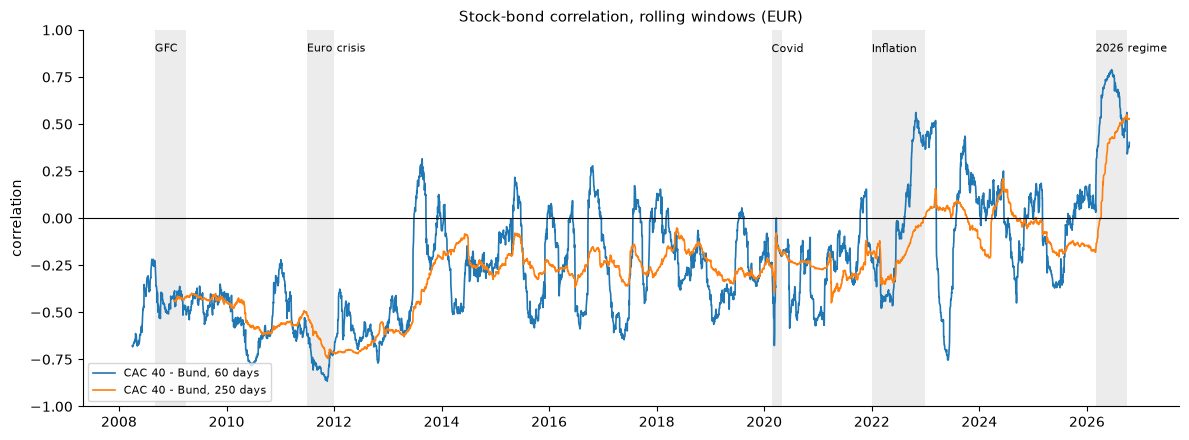

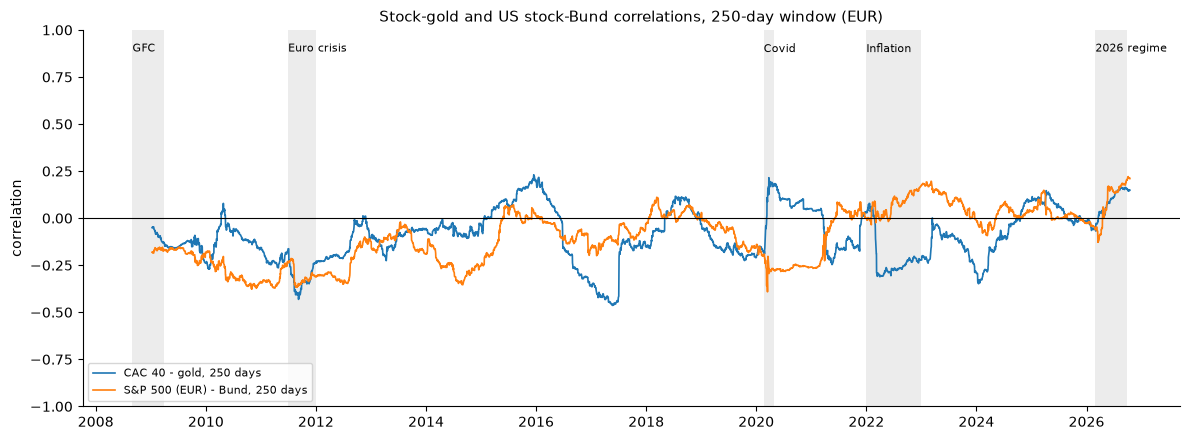

250-day CAC-Bund correlation: min -0.75 on 2011-11-22 | max 0.55 on 2026-09-30
60-day CAC-Bund correlation:  min -0.87 on 2011-11-16 | max 0.79 on 2026-06-18


In [ ]:
# Rolling correlations: stock-bond and stock-gold, 60 and 250 days
cols, idx = Y.columns, Y.index
R60 = cov_to_corr(rolling_cov(Y, window=60))
R250 = cov_to_corr(H_roll)

sb60 = pair_series(R60, cols, "CAC40", "BUND", idx)
sb250 = pair_series(R250, cols, "CAC40", "BUND", idx)

fig = plot_correlations({"CAC 40 - Bund, 60 days": sb60, "CAC 40 - Bund, 250 days": sb250},
                        "Stock-bond correlation, rolling windows (EUR)")
fig.savefig(FIGURES / "corr_stock_bond_rolling.png", dpi=150, bbox_inches="tight")
plt.show()

fig = plot_correlations({"CAC 40 - gold, 250 days": pair_series(R250, cols, "CAC40", "GOLD", idx),
                         "S&P 500 (EUR) - Bund, 250 days": pair_series(R250, cols, "SP500", "BUND", idx)},
                        "Stock-gold and US stock-Bund correlations, 250-day window (EUR)")
fig.savefig(FIGURES / "corr_gold_us_rolling.png", dpi=150, bbox_inches="tight")
plt.show()

# Extremes of the 250-day stock-bond correlation
print("250-day CAC-Bund correlation: min", round(sb250.min(), 2), "on", sb250.idxmin().date(),
      "| max", round(sb250.max(), 2), "on", sb250.idxmax().date())
print("60-day CAC-Bund correlation:  min", round(sb60.min(), 2), "on", sb60.idxmin().date(),
      "| max", round(sb60.max(), 2), "on", sb60.idxmax().date())

#### Findings – covariance basics and rolling correlations

- All identities hold to machine precision. The smallest eigenvalue (0.029) shows a **nearly singular** matrix:
  CAC and DAX are almost the same asset, so "long CAC, short DAX" looks almost risk-free — a trap for optimisers (Section 10).
- **Stock–bond correlation:** 60 days from −0.87 (November 2011) to +0.79 (June 2026); 250 days from −0.75 to +0.55.
- **The 250-day window is very late:** in March 2026 the 60-day correlation had crossed zero, the 250-day one was
  still −0.17 and only peaked in September. It can also flip within weeks (March 2023: +0.5 to −0.75).
- **Ghost effect:** the CAC–gold correlation jumps in March 2020 and drops back exactly one year later.

## 3. EWMA covariance

### 3.1 The EWMA covariance (`ewma_cov`)

1. **What do I need to determine?** a covariance forecast that reacts quickly and smoothly, with no ghost effect.
2. **Information and assumptions:** λ = 0.94 for every element; starting matrix = average of the first 250 days.
3. **Method:** Equation 8: $H_t = (1-\lambda)\mathbf{y}_{t-1}\mathbf{y}_{t-1}' + \lambda H_{t-1}$.
4. **Why it works:** old days fade gradually (half-life about 11 days); positive definite by construction.
5. **How I verify it:** (a) equal to pandas' ewm; (b) positive definite every day; (c) one day by hand.

In [ ]:
# EWMA covariance: three checks
H_ewma = ewma_cov(Y, lam=0.94)

# (a) each element vs pandas ewm on the cross-products (after the starting value has faded)
lam = 0.94
a, b = "CAC40", "BUND"
i, j = list(cols).index(a), list(cols).index(b)
pandas_cov = (Y[a] * Y[b]).ewm(alpha=1 - lam, adjust=False).mean().shift(1)
diff = np.abs(H_ewma[500:, i, j] - pandas_cov.iloc[500:].to_numpy()).max()
print(f"(a) max |ours - pandas| for {a}-{b} after 500 days:", diff)

# (b) positive definite on every day
min_eig = np.linalg.eigvalsh(H_ewma).min(axis=1)
print("(b) smallest eigenvalue over all days:", round(min_eig.min(), 5), "on", idx[min_eig.argmin()].date())

# (c) one day by hand: Equation 8
t = 3000
y = Y.to_numpy()[t - 1]
by_hand = (1 - lam) * np.outer(y, y) + lam * H_ewma[t - 1]
print("(c) max |by hand - function| on", idx[t].date(), ":", np.abs(by_hand - H_ewma[t]).max())

(a) max |ours - pandas| for CAC40-BUND after 500 days: 1.5265566588595902e-14
(b) smallest eigenvalue over all days: 0.00648 on 2021-08-25
(c) max |by hand - function| on 2020-04-06 : 0.0


### 3.2 EWMA vs rolling windows: speed and noise

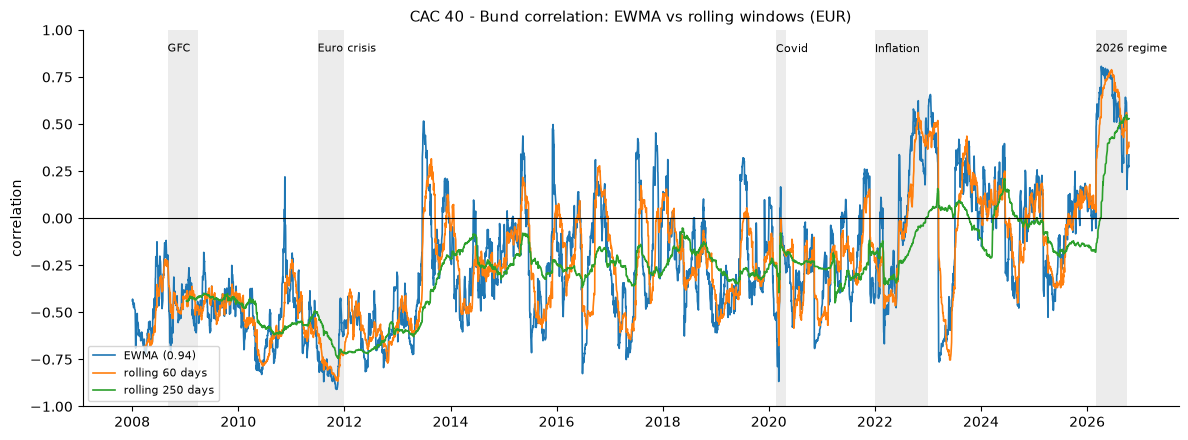

,first > 0 after 1 Mar 2026,avg |daily change|,change on 2021-03-16 (Covid leaves 250d window)
EWMA,2026-03-03,0.032079,-0.011547
60 days,2026-03-02,0.016347,-0.001539
250 days,2026-04-02,0.004193,0.001498


In [ ]:
# Stock-bond correlation: EWMA vs rolling windows
R_ewma = cov_to_corr(H_ewma)
sb_ewma = pair_series(R_ewma, cols, "CAC40", "BUND", idx)

fig = plot_correlations({"EWMA (0.94)": sb_ewma, "rolling 60 days": sb60, "rolling 250 days": sb250},
                        "CAC 40 - Bund correlation: EWMA vs rolling windows (EUR)")
fig.savefig(FIGURES / "corr_stock_bond_ewma.png", dpi=150, bbox_inches="tight")
plt.show()

def first_positive(s, after="2026-03-01"):
    """First date on/after `after` with a positive correlation."""
    s = s.loc[after:]
    return s[s > 0].index[0].date() if (s > 0).any() else None

speed_noise = pd.DataFrame({
    "first > 0 after 1 Mar 2026": {"EWMA": first_positive(sb_ewma), "60 days": first_positive(sb60),
                                   "250 days": first_positive(sb250)},
    "avg |daily change|": {"EWMA": sb_ewma.diff().abs().mean(), "60 days": sb60.diff().abs().mean(),
                           "250 days": sb250.diff().abs().mean()},
    "change on 2021-03-16 (Covid leaves 250d window)": {
        "EWMA": sb_ewma.diff().loc["2021-03-16"], "60 days": sb60.diff().loc["2021-03-16"],
        "250 days": sb250.diff().loc["2021-03-16"]},
})
speed_noise

#### Findings – EWMA

- EWMA matches pandas to 1.5e-14 and is positive definite every day, but its smallest eigenvalue (0.0065, August
  2021) is the lowest of all models: a short memory makes calm-period matrices nearly singular.
- **Speed vs noise:** the 250-day window turned positive in 2026 a month late (2 April); EWMA and 60 days early March.
  EWMA's correlation is the noisiest (average daily change 0.032, twice the 60-day window, 8 times the 250-day).
- The date chosen for the ghost-effect check (16 March 2021) missed the step; the chart shows it clearly in March 2024,
  when the SVB days of March 2023 left the 250-day window.

## 4. Univariate volatility and CCC

### 4.1 GJR-GARCH Student-t for each asset (`fit_gjr_t`, `gjr_variance`)

1. **What do I need to determine?** each asset's volatility forecast and standardised residuals, the inputs of CCC and DCC.
2. **Information and assumptions:** zero mean, Student-t shocks; γ may be negative (gold).
3. **Method:** maximum likelihood of $\sigma^2_t = \omega + (\alpha + \gamma I_{t-1})y^2_{t-1} + \beta\sigma^2_{t-1}$.
4. **Why it works:** the same model passed every test in Projects 2 and 3; each asset gets its own speed and asymmetry.
5. **How I verify it:** (a) parameters equal to the arch package; (b) all converge; (c) residual variance about 1.

In [ ]:
# GJR-GARCH Student-t for each asset: ours vs the arch package
rows, sig2 = {}, {}
for a in cols:
    ours = fit_gjr_t(Y[a])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ref = arch_model(Y[a], mean="Zero", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
    rows[a] = {"alpha": ours["alpha"], "gamma": ours["gamma"], "gamma_arch": ref.params["gamma[1]"],
               "beta": ours["beta"], "nu": ours["nu"], "nu_arch": ref.params["nu"],
               "persistence": ours["alpha"] + ours["gamma"] / 2 + ours["beta"],
               "converged": ours["converged"]}
    sig2[a] = gjr_variance(Y[a], ours["omega"], ours["alpha"], ours["gamma"], ours["beta"])

params_full = pd.DataFrame(rows).T
sig2 = pd.DataFrame(sig2)
eps = Y / np.sqrt(sig2)                                    # standardised residuals

print(params_full.round(3))
print("\nresidual variance (should be ~1):")
print(eps.var().round(3))

          alpha     gamma gamma_arch      beta        nu   nu_arch  \
CAC40       0.0  0.228138   0.227842   0.87336  6.511474  6.496772   
DAX         0.0  0.199451   0.198992  0.886206   6.34243  6.336707   
SP500  0.003915  0.205044   0.204823  0.867277  7.582301  7.571246   
BUND   0.045214   0.00538   0.005349  0.948863  8.747884  8.761568   
GOLD   0.077414 -0.024297  -0.024282  0.923608  5.573906  5.574682   

      persistence converged  
CAC40    0.987429      True  
DAX      0.985931      True  
SP500    0.973714      True  
BUND     0.996767      True  
GOLD     0.988874      True  

residual variance (should be ~1):
CAC40    1.001
DAX      0.989
SP500    1.004
BUND     1.006
GOLD     1.001
dtype: float64


### 4.2 CCC: constant conditional correlation (`qbar`, `ccc_cov`)

1. **What do I need to determine?** the CCC covariance: GJR volatilities with one constant correlation matrix.
2. **Information and assumptions:** residuals from 4.1; correlations assumed constant.
3. **Method:** Equation 9: $\bar R$ = correlation of the residuals (zero mean), $H_t = D_t\bar RD_t$.
4. **Why it works:** residuals no longer contain volatility swings; $ar Q$ is also the long-run target of DCC.
5. **How I verify it:** (a) valid matrix; (b) diagonal = GJR variances; (c) correlations of every $H_t$ = $ar R$; (d) vs raw correlations.

In [ ]:
# CCC: constant correlation of the residuals, GJR volatilities
R_bar = cov_to_corr(qbar(eps))
H_ccc = ccc_cov(sig2, R_bar)

# (a) valid correlation matrix
print("(a) diagonal = 1:", np.allclose(np.diag(R_bar), 1),
      "| smallest eigenvalue:", round(np.linalg.eigvalsh(R_bar).min(), 4))

# (b) diagonal of H = univariate GJR variances
print("(b) max |diag(H) - GJR variance|:", np.abs(np.diagonal(H_ccc, axis1=1, axis2=2) - sig2.to_numpy()).max())

# (c) correlations of every H_t equal R_bar
print("(c) max |corr(H_t) - R_bar| over all days:", np.abs(cov_to_corr(H_ccc) - R_bar).max())

# (d) residual correlations vs raw return correlations
print("\n(d) CCC correlation matrix (residuals):")
print(pd.DataFrame(R_bar, index=cols, columns=cols).round(2))
print("\ndifference vs raw return correlations (residual - raw):")
print((pd.DataFrame(R_bar, index=cols, columns=cols) - Y.corr()).round(2))

(a) diagonal = 1: True | smallest eigenvalue: 0.0973
(b) max |diag(H) - GJR variance|: 1.4210854715202004e-14
(c) max |corr(H_t) - R_bar| over all days: 4.440892098500626e-16

(d) CCC correlation matrix (residuals):
       CAC40   DAX  SP500  BUND  GOLD
CAC40   1.00  0.90   0.45 -0.24 -0.08
DAX     0.90  1.00   0.47 -0.22 -0.06
SP500   0.45  0.47   1.00 -0.08  0.11
BUND   -0.24 -0.22  -0.08  1.00  0.24
GOLD   -0.08 -0.06   0.11  0.24  1.00

difference vs raw return correlations (residual - raw):
       CAC40   DAX  SP500  BUND  GOLD
CAC40  -0.00 -0.02  -0.03  0.04  0.01
DAX    -0.02  0.00  -0.03  0.04  0.00
SP500  -0.03 -0.03   0.00  0.02  0.04
BUND    0.04  0.04   0.02  0.00  0.04
GOLD    0.01  0.00   0.04  0.04  0.00


#### Findings – univariate models and CCC

| | α | γ | half-life | reading |
|---|---|---|---|---|
| CAC 40 / DAX | 0.000 | 0.228 / 0.199 | 55 / 49 days | volatility reacts only to falls |
| S&P 500 (EUR) | 0.004 | 0.205 | 26 days | forgets faster (USD noise) |
| Bund | 0.045 | 0.005 | **214 days** | symmetric, long volatility regimes |
| Gold | 0.077 | **−0.024** | 62 days | inverse leverage; ν = 5.6, fattest tails |

- Our estimates match `arch` to 3–4 decimals; residual variances 0.99–1.01. EWMA's single 11-day half-life is wrong for every asset.
- **CCC:** smallest eigenvalue 0.097 (better conditioned than raw data). Residual correlations are slightly lower for
  equity pairs and less negative for stock–Bund: part of crisis "correlation" is really volatility.
- CCC's stock–Bund correlation is −0.24 on every day — including 2011 (−0.70) and 2026 (+0.62).

## 5. DCC: dynamic conditional correlation

### 5.1 The DCC recursion (`dcc_correlations`)

1. **What do I need to determine?** a correlation matrix that changes every day with yesterday's joint shocks.
2. **Information and assumptions:** residuals and long-run target $\bar Q$ from Step 4; two parameters a, b for all pairs.
3. **Method:** Equations 10–11: $Q_t = (1-a-b)\bar Q + a\,\boldsymbol\varepsilon_{t-1}\boldsymbol\varepsilon_{t-1}' + bQ_{t-1}$, rescaled to $R_t$.
4. **Why it works:** a GARCH(1,1) for correlations, with mean reversion; always a valid correlation matrix.
5. **How I verify it:** (a) theory example 0.639; (b) a = b = 0 gives CCC; (c) valid matrices on our data.

In [ ]:
# DCC recursion: three checks
# (a) Theory-note example: Q_bar correlation 0.5, a = 0.05, b = 0.93, crash day shocks (-3, -2.5)
E_ex = np.array([[-3.0, -2.5], [0.0, 0.0]])                    # day 0: crash; day 1: forecast after it
Qb_ex = np.array([[1.0, 0.5], [0.5, 1.0]])
R_ex = dcc_correlations(E_ex, a=0.05, b=0.93, Q_bar=Qb_ex)
print("(a) correlation after the crash day:", round(R_ex[1, 0, 1], 3), "| expected 0.639")

# (b) a = b = 0: DCC equals CCC every day
R0 = dcc_correlations(eps, a=0.0, b=0.0)
print("(b) max |DCC(0,0) - CCC|:", np.abs(R0 - R_bar).max())

# (c) typical parameters on our data: valid correlation matrices every day
R_dcc_test = dcc_correlations(eps, a=0.02, b=0.97)
print("(c) diagonal = 1:", np.allclose(np.diagonal(R_dcc_test, axis1=1, axis2=2), 1),
      "| smallest eigenvalue over all days:", round(np.linalg.eigvalsh(R_dcc_test).min(), 4))
sb_test = pair_series(R_dcc_test, cols, "CAC40", "BUND", idx)
print("    CAC-Bund correlation with a=0.02, b=0.97: min", round(sb_test.min(), 2), "| max", round(sb_test.max(), 2))

(a) correlation after the crash day: 0.639 | expected 0.639
(b) max |DCC(0,0) - CCC|: 0.0
(c) diagonal = 1: True | smallest eigenvalue over all days: 0.0325
    CAC-Bund correlation with a=0.02, b=0.97: min -0.71 | max 0.43


### 5.2 DCC log-likelihood and estimation (`dcc_loglik`, `fit_dcc`)

1. **What do I need to determine?** the a and b that best explain how residuals move together.
2. **Information and assumptions:** Gaussian quasi-likelihood (fat tails handled in the univariate step); a, b ≥ 0, a + b < 1.
3. **Method:** Equation 12: $\ell_C = -\frac12\sum[\ln|R_t| + \boldsymbol\varepsilon_t'R_t^{-1}\boldsymbol\varepsilon_t - \boldsymbol\varepsilon_t'\boldsymbol\varepsilon_t]$, SLSQP.
4. **Why it works:** the full Gaussian likelihood splits into a volatility part and this correlation part.
5. **How I verify it:** (a) equal to scipy's multivariate normal up to a constant; (b) recovers known parameters from simulated data.

In [ ]:
# DCC log-likelihood and estimation: two checks
# (a) vs scipy's multivariate normal on the first 300 days (a = 0.02, b = 0.97)
E300 = eps.iloc[:300].to_numpy()
Qb_full = qbar(eps)                                       # same long-run target for both
R300 = dcc_correlations(E300, 0.02, 0.97, Q_bar=Qb_full)
ours = dcc_loglik((0.02, 0.97), E300, Q_bar=Qb_full)
scipy_ll = sum(stats.multivariate_normal(mean=np.zeros(5), cov=R300[t]).logpdf(E300[t]) for t in range(300))
constant = 0.5 * np.sum(5 * np.log(2 * np.pi) + np.sum(E300 ** 2, axis=1))
print("(a) ours:", round(ours, 6), "| scipy + constant:", round(scipy_ll + constant, 6))

# (b) simulation: 3 assets, 4,000 days, true a = 0.05, b = 0.93
def simulate_dcc(T, a, b, Qb, seed=1):
    """Standardised residuals from a DCC process with known parameters."""
    g = np.random.default_rng(seed)
    N = len(Qb)
    E = np.zeros((T, N))
    Q = Qb.copy()
    for t in range(T):
        if t > 0:
            e = E[t - 1][:, None]
            Q = (1 - a - b) * Qb + a * (e @ e.T) + b * Q
        R = cov_to_corr(Q)
        E[t] = np.linalg.cholesky(R) @ g.standard_normal(N)      # shocks with correlation R_t
    return E

Qb_sim = np.array([[1.0, 0.6, -0.3], [0.6, 1.0, -0.2], [-0.3, -0.2, 1.0]])
E_sim = simulate_dcc(4000, 0.05, 0.93, Qb_sim)
fit_sim = fit_dcc(E_sim)
print("(b) true a = 0.05, b = 0.93 | estimated a =", round(fit_sim["a"], 3), ", b =", round(fit_sim["b"], 3),
      "| converged:", fit_sim["converged"])

(a) ours: 399.980719 | scipy + constant: 399.980719
(b) true a = 0.05, b = 0.93 | estimated a = 0.052 , b = 0.928 | converged: True


### 5.3 DCC on the 5 assets, and the test against CCC

1. **What do I need to determine?** the real a and b, whether correlations really change (DCC vs CCC), and the DCC stock–bond correlation.
2. **Information and assumptions:** full-sample GJR residuals (in-sample description; the honest test is Step 7).
3. **Method:** `fit_dcc`; Equation 13: $LR = 2[\ell_C(\hat a,\hat b) - \ell_C(0,0)]$ vs χ²(2); half-life $\ln 0.5/\ln(a+b)$.
4. **Why it works:** CCC is DCC with a = b = 0 (nested); a = 0 on the boundary makes χ²(2) conservative.
5. **How I verify it:** convergence; small a, b close to 1; DCC smoother than the 60-day window.

DCC: a = 0.0312, b = 0.9447, a + b = 0.9759, converged: True
half-life of a correlation shock: 28 days
log-likelihood: DCC 5229.8 | CCC 4785.4 | LR = 888.8, p-value (chi2(2), conservative) = 9.8e-194


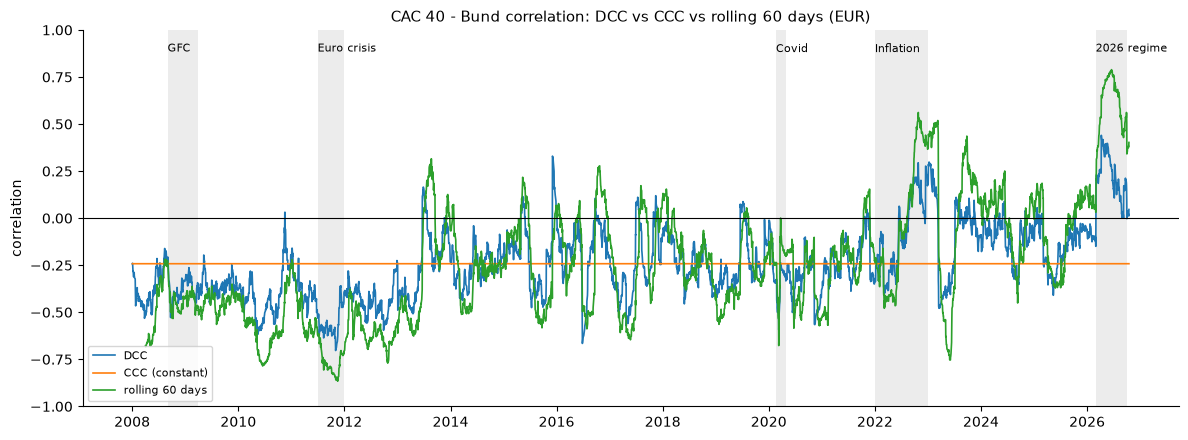


DCC CAC-Bund correlation: min -0.7 on 2011-11-02 | max 0.44 on 2026-04-09
average daily change: DCC 0.0179 | EWMA 0.0321 | 60 days 0.0163


In [ ]:
# DCC on the 5 assets (full sample), test against CCC, and the stock-bond correlation
dcc_full = fit_dcc(eps)
a_hat, b_hat = dcc_full["a"], dcc_full["b"]
ll_ccc = dcc_loglik((0.0, 0.0), eps)
LR = 2 * (dcc_full["loglik"] - ll_ccc)

print(f"DCC: a = {a_hat:.4f}, b = {b_hat:.4f}, a + b = {a_hat + b_hat:.4f}, converged: {dcc_full['converged']}")
print(f"half-life of a correlation shock: {np.log(0.5) / np.log(a_hat + b_hat):.0f} days")
print(f"log-likelihood: DCC {dcc_full['loglik']:.1f} | CCC {ll_ccc:.1f} | LR = {LR:.1f}, "
      f"p-value (chi2(2), conservative) = {stats.chi2.sf(LR, df=2):.2g}")

R_dcc = dcc_correlations(eps, a_hat, b_hat)
sb_dcc = pair_series(R_dcc, cols, "CAC40", "BUND", idx)
sb_ccc = pd.Series(R_bar[cols.get_loc("CAC40"), cols.get_loc("BUND")], index=idx)

fig = plot_correlations({"DCC": sb_dcc, "CCC (constant)": sb_ccc, "rolling 60 days": sb60},
                        "CAC 40 - Bund correlation: DCC vs CCC vs rolling 60 days (EUR)")
fig.savefig(FIGURES / "corr_stock_bond_dcc.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nDCC CAC-Bund correlation: min", round(sb_dcc.min(), 2), "on", sb_dcc.idxmin().date(),
      "| max", round(sb_dcc.max(), 2), "on", sb_dcc.idxmax().date())
print("average daily change: DCC", round(sb_dcc.diff().abs().mean(), 4),
      "| EWMA", round(sb_ewma.diff().abs().mean(), 4), "| 60 days", round(sb60.diff().abs().mean(), 4))

#### Findings – DCC

- Checks: the theory example gives 0.639; DCC(0, 0) = CCC exactly; the likelihood equals scipy's; simulated
  a = 0.05, b = 0.93 are recovered as 0.052, 0.928.
- **Full sample: a = 0.031, b = 0.945, half-life 28 days.** The data ask for slower, mean-reverting correlations
  than RiskMetrics (11 days, no long-run level).
- **Correlations are not constant: LR = 888.8** (DCC 5,229.8 vs CCC 4,785.4 log-points), p ≈ 10⁻¹⁹³.
- DCC's stock–bond correlation goes from −0.70 (November 2011) to +0.44 (9 April 2026), with half of EWMA's noise
  and no ghost effect. **It is "muted":** it peaks at +0.44 when the 60-day window reaches +0.79 and fades the 2026
  regime back towards the long-run −0.24 — mean reversion plus one (a, b) for all 10 pairs.

## 6. Correlations and portfolio risk in crises

### 6.1 Calm days vs stress periods (`dcc_cov`)

1. **What do I need to determine?** how correlations change in each stress period, and which model's portfolio volatility is closer to the realised one.
2. **Information and assumptions:** DCC and CCC with the same GJR volatilities; the CRISES periods; in-sample.
3. **Method:** average correlation of 5 pairs by period; average forecast portfolio volatility vs realised, by period.
4. **Why it works:** same volatilities: any difference comes only from the correlations.
5. **How I verify it:** both models close on calm days; DCC closer when the stock–bond correlation moved (2022, 2026).

In [ ]:
# Correlations and portfolio volatility: calm days vs stress periods (in-sample)
H_dcc = dcc_cov(sig2, R_dcc)

# Period label for every day: the crisis name, or "calm"
period = pd.Series("calm", index=idx)
for start, end, name in CRISES:
    period.loc[start:end] = name

pairs = [("CAC40", "DAX"), ("CAC40", "SP500"), ("CAC40", "BUND"), ("SP500", "BUND"), ("CAC40", "GOLD")]
corr_by_period = pd.DataFrame({f"{a}-{b}": pair_series(R_dcc, cols, a, b, idx) for a, b in pairs})
table_corr = corr_by_period.groupby(period).mean()

# Portfolio volatility, annualised %: forecast (DCC, CCC) vs realised
vol = pd.DataFrame({
    "DCC forecast": np.sqrt(portfolio_variance(H_dcc, w_vec) * 252),
    "CCC forecast": np.sqrt(portfolio_variance(H_ccc, w_vec) * 252),
}, index=idx)
table_vol = vol.groupby(period).mean()
table_vol["realised"] = Rp.groupby(period).std() * np.sqrt(252)
table_vol["days"] = period.value_counts()

order = ["calm", "GFC", "Euro crisis", "Covid", "Inflation", "2026 regime"]
print("Average DCC correlations by period:")
print(table_corr.loc[order].round(2))
print(f"\nCCC (every period): CAC40-BUND {R_bar[cols.get_loc('CAC40'), cols.get_loc('BUND')]:.2f}")
print("\nPortfolio volatility (60/30/10), annualised %:")
print(table_vol.loc[order].round(2))

Average DCC correlations by period:
             CAC40-DAX  CAC40-SP500  CAC40-BUND  SP500-BUND  CAC40-GOLD
calm              0.90         0.45       -0.25       -0.09       -0.08
GFC               0.93         0.49       -0.38       -0.13       -0.13
Euro crisis       0.93         0.46       -0.57       -0.20       -0.22
Covid             0.94         0.64       -0.36       -0.31        0.08
Inflation         0.92         0.41       -0.08        0.04       -0.04
2026 regime       0.86         0.38        0.23        0.12        0.09

CCC (every period): CAC40-BUND -0.24

Portfolio volatility (60/30/10), annualised %:
             DCC forecast  CCC forecast  realised  days
calm                 8.93          8.94      8.92  3894
GFC                 24.20         24.34     27.63   141
Euro crisis         15.74         16.74     16.40   124
Covid               30.81         29.00     34.78    49
Inflation           11.67         11.36     12.04   248
2026 regime          9.38          8.4

#### Findings – crises

- **Equities move together in crashes:** CAC–S&P 0.45 (calm) → 0.64 (Covid); CAC–DAX 0.93–0.94.
- **Bunds hedged the old crises** (CAC–Bund −0.38 GFC, −0.57 euro crisis) **but not the new regimes** (−0.08 in 2022,
  +0.23 in 2026). Gold hedged the GFC and the euro crisis, not Covid.
- **Portfolio volatility:** both models match calm days (8.93 / 8.94 vs 8.92). DCC is closer in Covid, 2022 and
  2026 (2026: CCC 17% too low, DCC 9%); CCC is closer in the euro crisis, where DCC was too optimistic about the
  hedge. Every model is too low in every crisis: forecasts react only after the first big days.

## 7. Out-of-sample forecasts

### 7.1 Rolling CCC and DCC: look-ahead test on a small sample (`rolling_ccc_dcc`)

1. **What do I need to determine?** CCC and DCC forecasts for each day after the first 1,000, using only past data.
2. **Information and assumptions:** 1,000-day estimation window, re-estimated every 20 days.
3. **Method:** per block: 5 GJR fits on the window, residuals, Q̄ and (a, b) from the window only, recursions through the block.
4. **Why it works:** every parameter is estimated before the block; every forecast for day t uses returns up to t − 1.
5. **How I verify it:** (a) a fake crash leaves forecasts up to its own day unchanged and changes the next; (b) shape and dates; (c) same variances in CCC and DCC.

In [ ]:
# Rolling CCC/DCC: look-ahead test and shape checks on a small sample (1,100 days, 5 blocks)
Ys = Y.iloc[:1100]
Hc, Hd, ps = rolling_ccc_dcc(Ys, window=1000, refit_every=20)

# (b) shape and dates
print("(b) forecasts:", Hc.shape, "| expected (100, 5, 5) | blocks:", len(ps), "| first date:", Ys.index[1000].date())

# (c) same variances in CCC and DCC
print("(c) max |diag CCC - diag DCC|:", np.abs(np.diagonal(Hc, axis1=1, axis2=2) - np.diagonal(Hd, axis1=1, axis2=2)).max())

# (a) look-ahead: a fake -20% CAC day at position 1050 (inside block 3, out-of-sample day 50)
fake = Ys.copy()
fake.iloc[1050, 0] = -20.0
Hc_f, Hd_f, _ = rolling_ccc_dcc(fake, window=1000, refit_every=20)
print("(a) forecasts up to and including the fake day unchanged:",
      np.array_equal(Hd[:51], Hd_f[:51]), "| next day changed:", not np.allclose(Hd[51], Hd_f[51]))
print("    DCC a, b per block:", ps[["a", "b"]].round(3).values.tolist())

(b) forecasts: (100, 5, 5) | expected (100, 5, 5) | blocks: 5 | first date: 2012-01-23
(c) max |diag CCC - diag DCC|: 1.3322676295501878e-15
(a) forecasts up to and including the fake day unchanged: True | next day changed: True
    DCC a, b per block: [[0.04, 0.912], [0.039, 0.914], [0.038, 0.916], [0.038, 0.916], [0.038, 0.914]]


### 7.2 The full out-of-sample run (computed once, then loaded)

In [ ]:
# Out-of-sample covariance forecasts for all models (computed once, then loaded)
WINDOW = 1000
oos = idx[WINDOW:]                                               # out-of-sample (oos) days

f_ccc, f_dcc, f_par = OUT / "H_ccc_oos.npy", OUT / "H_dcc_oos.npy", OUT / "dcc_params_oos.csv"
if f_dcc.exists():
    H_ccc_oos, H_dcc_oos = np.load(f_ccc), np.load(f_dcc)
    dcc_params = pd.read_csv(f_par, index_col=0, parse_dates=True)
    print("loaded from", OUT)
else:
    t0 = time.time()
    H_ccc_oos, H_dcc_oos, dcc_params = rolling_ccc_dcc(Y, window=WINDOW, refit_every=20)
    np.save(f_ccc, H_ccc_oos)
    np.save(f_dcc, H_dcc_oos)
    dcc_params.to_csv(f_par)
    print(f"computed in {(time.time() - t0) / 60:.1f} minutes and saved")

H_oos = {
    "Rolling 250": H_roll[WINDOW:],
    "EWMA": H_ewma[WINDOW:],
    "CCC": H_ccc_oos,
    "DCC": H_dcc_oos,
}

# Checks
print(f"\nout-of-sample days: {len(oos)}, {oos[0].date()} to {oos[-1].date()}")
for name, H in H_oos.items():
    print(f"{name:12s} shape {H.shape} | smallest eigenvalue {np.linalg.eigvalsh(H).min():.5f}")
print("\nDCC re-estimations:", len(dcc_params), "| not converged:", int((~dcc_params["dcc_converged"].astype(bool)).sum()))
print("a from", round(dcc_params["a"].min(), 3), "to", round(dcc_params["a"].max(), 3),
      "| b from", round(dcc_params["b"].min(), 3), "to", round(dcc_params["b"].max(), 3))

computed in 5.9 minutes and saved

out-of-sample days: 3602, 2012-01-23 to 2026-10-16
Rolling 250  shape (3602, 5, 5) | smallest eigenvalue 0.02040
EWMA         shape (3602, 5, 5) | smallest eigenvalue 0.00648
CCC          shape (3602, 5, 5) | smallest eigenvalue 0.02159
DCC          shape (3602, 5, 5) | smallest eigenvalue 0.02160

DCC re-estimations: 181 | not converged: 0
a from 0.021 to 0.045 | b from 0.87 to 0.946


#### Findings – out-of-sample run

- The look-ahead test passes; the test period starts on **23 January 2012**.
- **3,602 days per model**, 181 re-estimations, all converged, every matrix positive definite (EWMA's smallest
  eigenvalue lowest, 0.0065; CCC and DCC about 0.022).
- DCC parameters move across windows: a 0.021–0.045, b 0.87–0.946 (2008–2011 windows: a ≈ 0.04, b ≈ 0.91).

## 8. Forecast accuracy

### 8.1 Loss functions and test (`qlike_matrix`, `qlike_portfolio`, `diebold_mariano`)

1. **What do I need to determine?** which model forecasts the covariance best, and whether differences are significant.
2. **Information and assumptions:** $\mathbf{y}_t\mathbf{y}_t'$ is a noisy, unbiased proxy of the true covariance.
3. **Method:** matrix QLIKE $\ln|H_t| + \mathbf{y}_t'H_t^{-1}\mathbf{y}_t$; portfolio QLIKE; Diebold–Mariano with Newey–West (10 lags).
4. **Why it works:** QLIKE ranks models correctly with a noisy proxy; the matrix version judges every direction, the portfolio version the one held.
5. **How I verify it:** (a) one asset = univariate QLIKE; (b) equal to scipy's log-density up to a constant; (c) DM ≈ 0 against itself + noise.

In [ ]:
# Loss functions: three checks
Y_oos = Y.loc[oos].to_numpy()

# (a) one asset: matrix QLIKE = univariate QLIKE
h1 = H_dcc_oos[:, :1, :1]
L1 = qlike_matrix(h1, Y_oos[:, :1])
print("(a) max |matrix - univariate| for one asset:",
      np.abs(L1 - (np.log(h1[:, 0, 0]) + Y_oos[:, 0] ** 2 / h1[:, 0, 0])).max())

# (b) vs scipy's multivariate normal log-density (first 200 days)
L = qlike_matrix(H_dcc_oos[:200], Y_oos[:200])
scipy_ll = np.array([stats.multivariate_normal(np.zeros(5), H_dcc_oos[t]).logpdf(Y_oos[t]) for t in range(200)])
print("(b) max |-0.5 (L + N log 2pi) - scipy|:", np.abs(-0.5 * (L + 5 * np.log(2 * np.pi)) - scipy_ll).max())

# (c) DM of a model against itself plus noise with zero mean
loss = qlike_matrix(H_dcc_oos, Y_oos)
noise = np.random.default_rng(0).normal(0, 0.1, len(loss))
print("(c) DM vs itself + noise:", np.round(diebold_mariano(loss, loss + noise), 3))

(a) max |matrix - univariate| for one asset: 7.105427357601002e-15
(b) max |-0.5 (L + N log 2pi) - scipy|: 1.0391687510491465e-13
(c) DM vs itself + noise: [1.31 0.19]


### 8.2 Scores of the 4 models

In [ ]:
# Out-of-sample scores: matrix and portfolio QLIKE, Diebold-Mariano vs DCC, by period
Rp_oos = Rp.loc[oos].to_numpy()

loss_mat = pd.DataFrame({m: qlike_matrix(H, Y_oos) for m, H in H_oos.items()}, index=oos)
loss_pf = pd.DataFrame({m: qlike_portfolio(portfolio_variance(H, w_vec), Rp_oos) for m, H in H_oos.items()},
                       index=oos)

scores = pd.DataFrame({
    "matrix QLIKE": loss_mat.mean(),
    "rank (matrix)": loss_mat.mean().rank().astype(int),
    "DM vs DCC (matrix)": [diebold_mariano(loss_mat[m], loss_mat["DCC"])[0] if m != "DCC" else np.nan
                           for m in H_oos],
    "portfolio QLIKE": loss_pf.mean(),
    "rank (portfolio)": loss_pf.mean().rank().astype(int),
    "DM vs DCC (portfolio)": [diebold_mariano(loss_pf[m], loss_pf["DCC"])[0] if m != "DCC" else np.nan
                              for m in H_oos],
})
print("Out-of-sample scores, 2012-2026 (lower QLIKE = better; positive DM = worse than DCC):")
print(scores.round(3))

# Average matrix QLIKE by period: calm vs stress
period_oos = period.loc[oos]
by_period = loss_mat.groupby(period_oos).mean()
by_period["days"] = period_oos.value_counts()
print("\nMatrix QLIKE by period:")
print(by_period.loc[[p for p in order if p in by_period.index]].round(3))

Out-of-sample scores, 2012-2026 (lower QLIKE = better; positive DM = worse than DCC):
             matrix QLIKE  rank (matrix)  DM vs DCC (matrix)  portfolio QLIKE  \
Rolling 250         1.031              4               3.805           -0.023   
EWMA                0.717              3               6.776           -0.202   
CCC                 0.387              2               7.041           -0.256   
DCC                 0.269              1                 NaN           -0.261   

             rank (portfolio)  DM vs DCC (portfolio)  
Rolling 250                 4                  3.351  
EWMA                        3                  3.922  
CCC                         2                  1.846  
DCC                         1                    NaN  

Matrix QLIKE by period:
             Rolling 250    EWMA     CCC     DCC  days
calm               0.256   0.226  -0.113  -0.210  3159
Covid             29.910  14.377  11.112  10.485    49
Inflation          4.889   3.820   3.819   

### 8.3 Chart: accuracy of the 4 models (`plot_scores`)

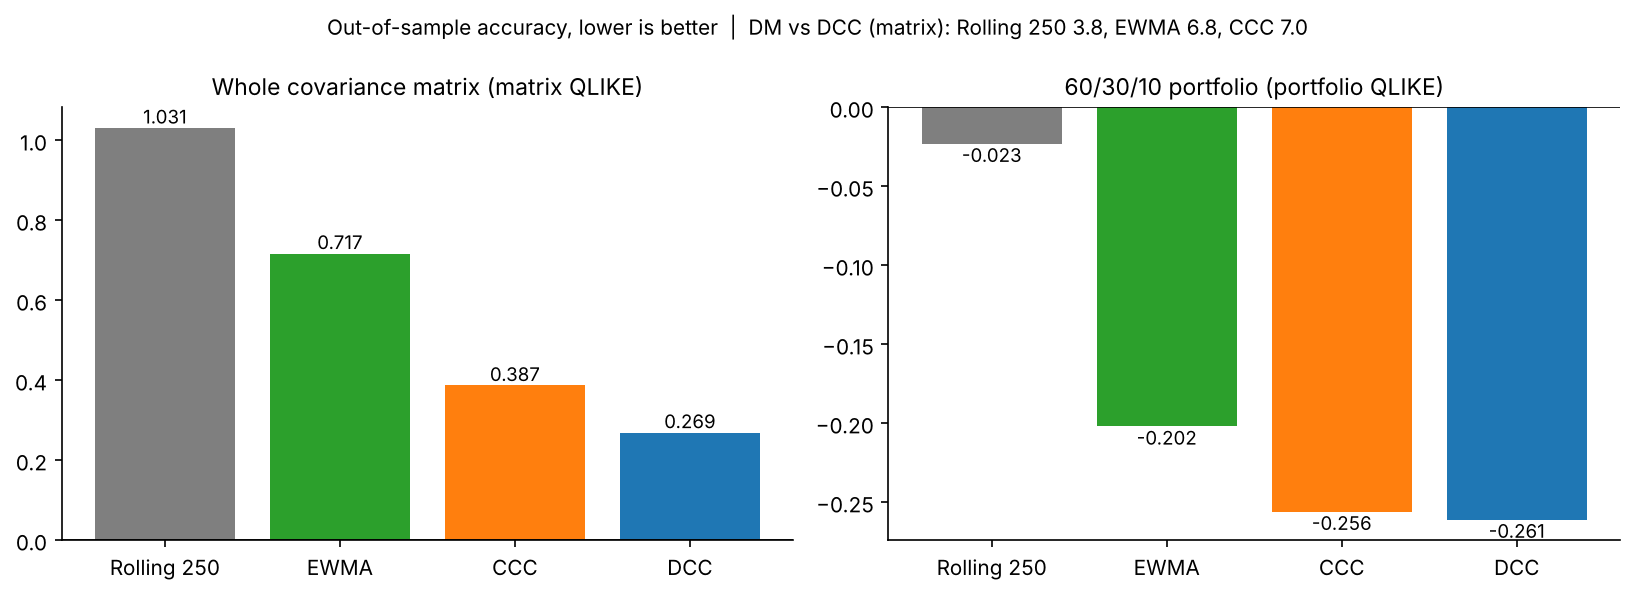

In [ ]:
# Matrix and portfolio QLIKE per model (lower is better), with the DM statistics vs DCC
fig = plot_scores(scores)
fig.savefig(FIGURES / "scores.png", dpi=150, bbox_inches="tight")
plt.show()

#### Findings – forecast accuracy (3,602 days, 2012–2026)

- **Whole matrix: DCC wins clearly** — QLIKE 0.269 vs CCC 0.387, EWMA 0.717, rolling 1.031; DM 7.0, 6.8, 3.8 (all significant).
- **60/30/10 portfolio: DCC ≈ CCC** (−0.261 vs −0.256, DM 1.85, p ≈ 0.06), both clearly ahead of EWMA and rolling.
  For one balanced portfolio the GJR volatilities do most of the work; correlation dynamics matter for other
  portfolios (hedges, long–short, minimum variance).
- **By period:** DCC best on calm days, in Covid and in 2022; **in 2026 EWMA (1.488) ≈ DCC (1.499), CCC worst (1.769)** —
  a lasting new regime favours fast forgetting.

## 9. Portfolio VaR and ES

### 9.1 VaR and ES functions (`var_es_normal`, `var_es_fhs`)

1. **What do I need to determine?** the 60/30/10 portfolio's VaR 99% and ES 97.5% from each covariance model.
2. **Information and assumptions:** $\sigma_{p,t} = \sqrt{\mathbf{w}'H_t\mathbf{w}}$; normal tails, or FHS on past standardised portfolio residuals (≥ 250).
3. **Method:** Equation 16: $\text{VaR}_t = \sigma_{p,t}k_{VaR}$, $\text{ES}_t = \sigma_{p,t}k_{ES}$.
4. **Why it works:** the covariance model sets the level of risk, the residuals the shape of the tail.
5. **How I verify it:** (a) normal multipliers; (b) FHS converges to them on normal data; (c) no look-ahead.

In [ ]:
# Portfolio VaR/ES functions: three checks
# (a) normal multipliers
v, e = var_es_normal(1.0)
print("(a) normal multipliers: VaR 99%", round(float(v), 4), "| ES 97.5%", round(float(e), 4))

# (b) FHS on iid normal residuals: multipliers converge to the normal ones
g = np.random.default_rng(3)
z_sim = g.standard_normal(20_000)
v_f, e_f = var_es_fhs(z_sim, np.ones(20_000), min_obs=250)
print("(b) FHS multipliers on the last day: VaR", round(v_f[-1], 3), "| ES", round(e_f[-1], 3), "(normal: 2.326, 2.338)")

# (c) look-ahead: an extreme residual on day 5,000 must not change that day's VaR
z_fake = z_sim.copy()
z_fake[5000] = -50.0
v_fake, _ = var_es_fhs(z_fake, np.ones(20_000), min_obs=250)
print("(c) VaR on the fake day unchanged:", v_fake[5000] == v_f[5000],
      "| later VaR uses it (ES changes next day):", var_es_fhs(z_fake, np.ones(20_000))[1][5001] != e_f[5001])

(a) normal multipliers: VaR 99% 2.3263 | ES 97.5% 2.3378
(b) FHS multipliers on the last day: VaR 2.314 | ES 2.318 (normal: 2.326, 2.338)
(c) VaR on the fake day unchanged: True | later VaR uses it (ES changes next day): True


### 9.2 Backtests for each model and tail (`kupiec_test`, `christoffersen_test`, `acerbi_szekely_z2`)

1. **What do I need to determine?** whether each model × tail passes the Project 3 backtests.
2. **Information and assumptions:** 3,352 test days (February 2013 – October 2026); 33.5 breaches expected at 99%, 83.8 at 97.5%.
3. **Method:** Kupiec, Christoffersen conditional coverage, Kupiec at 97.5%, Acerbi–Szekely Z₂ (5% critical value about −0.17).
4. **Why it works:** if the forecast distribution is right, breaches are iid Bernoulli(p) and tail losses average the ES.
5. **How I verify it:** normal tails fail; FHS close to the expected numbers.

In [ ]:
# Portfolio VaR 99% / ES 97.5% for each covariance model, normal and FHS tails, and backtests
MIN_OBS = 250
test_days = oos[MIN_OBS:]
r_test = Rp_oos[MIN_OBS:]

rows, var99_all = {}, {}
for m, H in H_oos.items():
    sig_p = np.sqrt(portfolio_variance(H, w_vec))                       # portfolio volatility forecast
    for tail in ["normal", "FHS"]:
        if tail == "normal":
            v99, es = var_es_normal(sig_p, p_var=0.01, p_es=0.025)
            v975, _ = var_es_normal(sig_p, p_var=0.025)
        else:
            v99, es = var_es_fhs(Rp_oos, sig_p, p_var=0.01, p_es=0.025, min_obs=MIN_OBS)
            v975, _ = var_es_fhs(Rp_oos, sig_p, p_var=0.025, min_obs=MIN_OBS)
        v99, es, v975 = v99[MIN_OBS:], es[MIN_OBS:], v975[MIN_OBS:]     # same 3,352 days for every method

        hits99 = r_test < -v99
        x99, p_k99 = kupiec_test(hits99, 0.01)
        n11, p_cc = christoffersen_test(hits99, 0.01)
        x975, p_k975 = kupiec_test(r_test < -v975, 0.025)
        rows[(m, tail)] = {"breaches 99%": x99, "Kupiec p": p_k99, "n11": n11, "p_cc": p_cc,
                           "breaches 97.5%": x975, "Kupiec 97.5 p": p_k975,
                           "Z2 (ES)": acerbi_szekely_z2(r_test, v975, es),
                           "avg VaR 99% (EUR k)": v99.mean() / 100 * 1e4}
        var99_all[(m, tail)] = v99

bt = pd.DataFrame(rows).T
print(f"test days: {len(test_days)}, {test_days[0].date()} to {test_days[-1].date()} | "
      f"expected breaches: 99% {0.01 * len(test_days):.1f}, 97.5% {0.025 * len(test_days):.1f}")
bt.round(3)

test days: 3352, 2013-02-01 to 2026-10-16 | expected breaches: 99% 33.5, 97.5% 83.8


breaches 99%  Kupiec p   n11   p_cc  breaches 97.5%  \
Rolling 250 normal          75.0     0.000  14.0  0.000           109.0   
            FHS             53.0     0.002  11.0  0.000           114.0   
EWMA        normal          76.0     0.000   5.0  0.000           119.0   
            FHS             41.0     0.210   2.0  0.121            88.0   
CCC         normal          60.0     0.000   1.0  0.000           111.0   
            FHS             43.0     0.115   1.0  0.248            94.0   
DCC         normal          60.0     0.000   1.0  0.000           107.0   
            FHS             42.0     0.157   1.0  0.308            96.0   

                    Kupiec 97.5 p  Z2 (ES)  avg VaR 99% (EUR k)  
Rolling 250 normal          0.008   -0.673              136.590  
            FHS             0.002   -0.446              164.394  
EWMA        normal          0.000   -0.700              130.459  
            FHS             0.645   -0.099              166.237  
CCC         normal          0.004   -0.491              132.095  
            FHS             0.268   -0.140              148.013  
DCC         normal          0.014   -0.441              133.400  
            FHS             0.187   -0.160              147.978

### 9.3 Chart: breaches and VaR level (`plot_var_backtest`)

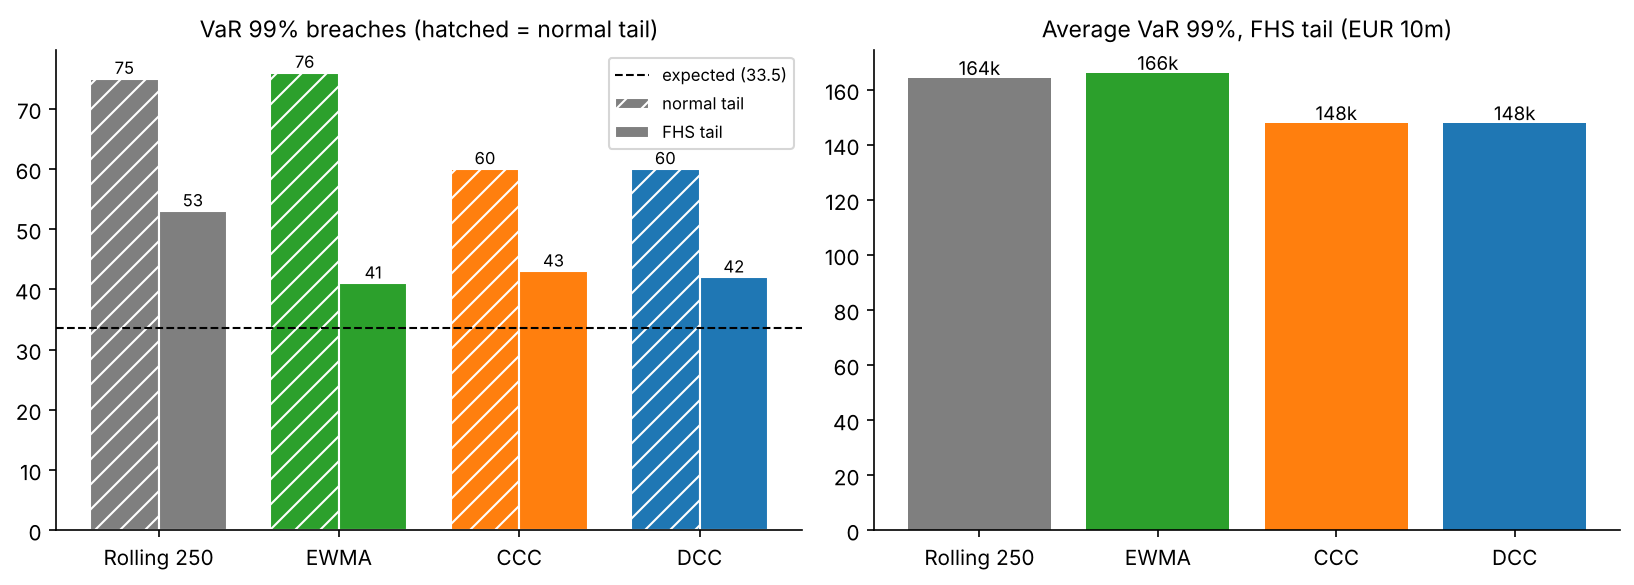

In [ ]:
# VaR 99% breaches per model (normal vs FHS tails) and the average FHS VaR of each model
fig = plot_var_backtest(bt, expected=0.01 * len(test_days))
fig.savefig(FIGURES / "var_backtest.png", dpi=150, bbox_inches="tight")
plt.show()

#### Findings – portfolio VaR and ES

- **Normal tails fail with every covariance model** (60–76 breaches vs 33.5; Z₂ −0.44 to −0.70).
- **With FHS tails:** rolling 250 fails (53 breaches, 11 consecutive: no tail fixes bad timing); **EWMA, CCC and DCC
  pass** (41, 43, 42 breaches; p_cc 0.12–0.31; 97.5% breaches 88–96).
- **CCC and DCC pass with 11% less VaR than EWMA** (EUR 148k vs 166k): noisier volatility gives noisier residuals and
  bigger multipliers. A better covariance model makes the same safety cheaper.
- DCC's Z₂ (−0.16) is close to the approximate critical value (−0.17); DCC, CCC and EWMA cannot be separated on ES
  without simulated p-values.

## 10. Minimum-variance portfolios

### 10.1 Weights and the out-of-sample strategy (`min_variance_weights`, `turnover`)

1. **What do I need to determine?** which model's daily minimum-variance portfolio is really least volatile out of sample, and what it costs to follow.
2. **Information and assumptions:** fully invested, short sales allowed, daily rebalancing; turnover measured separately.
3. **Method:** Equation 17: $\mathbf{w}_t = H_t^{-1}\mathbf{1}/(\mathbf{1}'H_t^{-1}\mathbf{1})$; realised volatility, turnover, largest position.
4. **Why it works:** the minimum-variance portfolio depends only on the covariance, and uses every correlation through $H^{-1}$.
5. **How I verify it:** (a) closed form for 2 assets (21% / 79%); (b) weights sum to 1; (c) lower forecast variance than 60/30/10.

In [ ]:
# Minimum-variance portfolios: checks, then the out-of-sample strategy for each model
# (a) two assets: closed form (stocks 1.2%, bonds 0.5%, correlation -0.3)
w2 = min_variance_weights(H_ex)
s1, s2, s12 = H_ex[0, 0], H_ex[1, 1], H_ex[0, 1]
print("(a) weights:", w2.round(4), "| closed form w1:", round((s2 - s12) / (s1 + s2 - 2 * s12), 4))

rows, W_mv = {}, {}
for m, H in H_oos.items():
    W = min_variance_weights(H)                                       # (3602, 5)
    W_mv[m] = W
    r_mv = np.sum(W * Y_oos, axis=1)                                  # realised return of the MV portfolio
    rows[m] = {
        "realised vol % (annual)": r_mv.std() * np.sqrt(252),
        "avg turnover % / day": 100 * np.nanmean(turnover(W)),
        "max |weight|": np.abs(W).max(),
        "avg short (sum of negative weights)": W.clip(max=0).sum(axis=1).mean(),
        "weights sum to 1": np.allclose(W.sum(axis=1), 1),
        "MV var < 60/30/10 var": bool(np.all(portfolio_variance(H, w_vec) >= np.einsum("ti,tij,tj->t", W, H, W) - 1e-12)),
    }

mv = pd.DataFrame(rows).T
print(f"\nfor reference, the 60/30/10 portfolio: realised vol {Rp_oos.std() * np.sqrt(252):.2f}% a year")
mv.round(3)

(a) weights: [0.2098 0.7902] | closed form w1: 0.2098

for reference, the 60/30/10 portfolio: realised vol 9.72% a year


,realised vol % (annual),avg turnover % / day,max |weight|,avg short (sum of negative weights),weights sum to 1,MV var < 60/30/10 var
Rolling 250,4.402275,0.904431,1.048333,-0.023577,True,True
EWMA,4.446676,8.161357,1.249752,-0.079476,True,True
CCC,4.461791,5.027801,1.01132,-0.016502,True,True
DCC,4.389414,6.47023,1.017629,-0.026436,True,True


### 10.2 Significance and trading costs

1. **What do I need to determine?** (a) whether realised-variance differences are significant; (b) the ranking after trading costs.
2. **Information and assumptions:** strategy returns from 10.1; costs of 2, 5 and 10 bp per unit of turnover.
3. **Method:** (a) Diebold–Mariano on squared strategy returns (Engle–Colacito); (b) net return = gross − cost × turnover.
4. **Why it works:** squared returns measure realised variance; costs turn turnover into money.
5. **How I verify it:** at 0 bp the net figures equal the gross ones; cost ≈ turnover × 252 × cost.

In [ ]:
# Significance of the volatility differences (DM on squared returns) and the effect of trading costs
R_mv = pd.DataFrame({m: np.sum(W * Y_oos, axis=1) for m, W in W_mv.items()}, index=oos)
TO = pd.DataFrame({m: np.nan_to_num(turnover(W)) for m, W in W_mv.items()}, index=oos)

# (a) DM on squared returns: positive = model has higher realised variance than DCC
dm = {m: diebold_mariano(R_mv[m] ** 2, R_mv["DCC"] ** 2) for m in R_mv if m != "DCC"}
print("(a) DM vs DCC on squared MV returns (positive = DCC less volatile):")
print({m: (round(s, 2), round(p, 3)) for m, (s, p) in dm.items()})

# (b) net of trading costs
rows = {}
for bp in [0, 2, 5, 10]:
    net = R_mv - TO * bp / 100                       # cost in % of the portfolio (1 bp = 0.01%)
    for m in R_mv:
        rows[(bp, m)] = {"annual return % (net)": net[m].mean() * 252,
                         "annual vol % (net)": net[m].std() * np.sqrt(252),
                         "annual cost %": TO[m].mean() * 252 * bp / 100}
costs = pd.DataFrame(rows).T
costs.index.names = ["cost (bp)", "model"]
print("\n(b) minimum-variance strategies net of trading costs:")
print(costs.round(3))

(a) DM vs DCC on squared MV returns (positive = DCC less volatile):
{'Rolling 250': (np.float64(0.25), np.float64(0.806)), 'EWMA': (np.float64(1.15), np.float64(0.248)), 'CCC': (np.float64(3.38), np.float64(0.001))}

(b) minimum-variance strategies net of trading costs:
                       annual return % (net)  annual vol % (net)  \
cost (bp) model                                                    
0         Rolling 250                  2.376               4.403   
          EWMA                         2.315               4.447   
          CCC                          1.829               4.462   
          DCC                          1.883               4.390   
2         Rolling 250                  2.330               4.403   
          EWMA                         1.903               4.448   
          CCC                          1.576               4.463   
          DCC                          1.557               4.391   
5         Rolling 250                  2.262     

### 10.3 Chart: risk, turnover and costs (`plot_mv_tradeoff`)

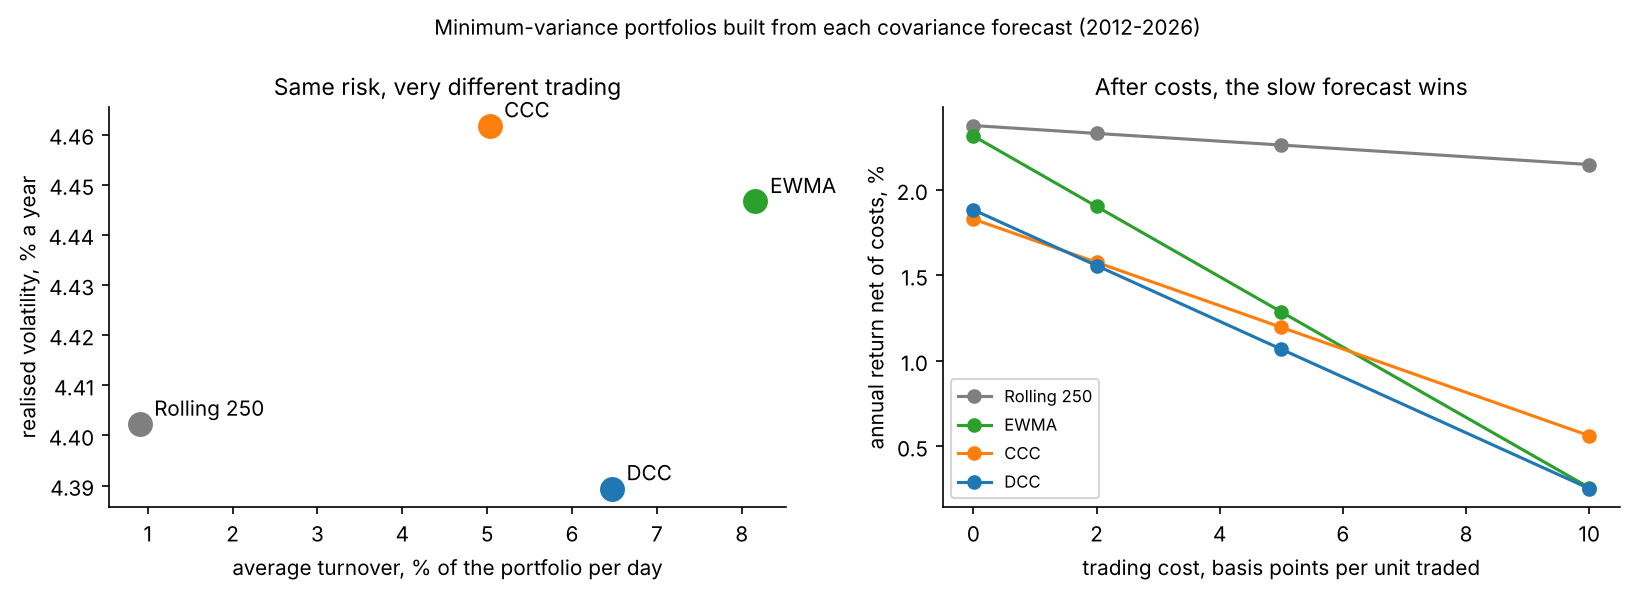

In [ ]:
# Realised volatility vs turnover, and net return vs trading cost, for the 4 minimum-variance strategies
fig = plot_mv_tradeoff(mv, costs)
fig.savefig(FIGURES / "mv_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

#### Findings – minimum-variance portfolios

- **Every model halves the risk:** about 4.4% realised volatility vs 9.72% for 60/30/10 (mostly Bunds).
- **DCC is least volatile (4.389%)**, significantly better than CCC (DM 3.38, p = 0.001) but **not** than rolling
  (p = 0.81) or EWMA (p = 0.25). The y-axis of the chart is zoomed: the whole range is 0.07 points.
- **Turnover decides:** EWMA trades 8.2% a day with up to 125% in one asset (near-singular CAC/DAX bets), DCC 6.5%,
  CCC 5.0%, **rolling 0.9%**. At 5 bp, DCC loses 0.82% a year to costs, rolling 0.11%.
- **After costs the slow rolling window is best** (2.26% net at 5 bp vs 1.07% for DCC). Different jobs need different
  models: DCC to *measure* risk, a smooth forecast (or a smoothed DCC) to *build* portfolios.

## 11. Conclusions and recommendations

**Business question:** how should a buy-side risk team forecast the covariance matrix of a multi-asset portfolio, and does a dynamic-correlation model give better risk numbers and better portfolios than constant or rolling correlations?

**Data:** CAC 40, DAX, S&P 500, German Bunds 5.5–10.5y (iShares EXHD, total return rebuilt), gold (GLD); all in EUR; 4,602 common days, January 2008 – October 2026. Out-of-sample test: 3,602 days, January 2012 – October 2026 (1,000-day estimation window, re-estimated every 20 days).

### 11.1 Main results

| | Rolling 250 | EWMA | CCC | DCC |
|---|---|---|---|---|
| Matrix QLIKE (rank) | 1.031 (4) | 0.717 (3) | 0.387 (2) | **0.269 (1)** |
| DM vs DCC (matrix) | 3.8 | 6.8 | 7.0 | – |
| Portfolio QLIKE, 60/30/10 | −0.023 | −0.202 | −0.256 | **−0.261** |
| VaR 99% breaches, FHS (33.5 exp.) | 53 ✗ | 41 | 43 | 42 |
| Avg VaR 99%, FHS (EUR 10m) | 164k | 166k | 148k | **148k** |
| Min-variance realised vol | 4.40% | 4.45% | 4.46% | **4.39%** |
| Min-variance turnover / day | **0.9%** | 8.2% | 5.0% | 6.5% |
| Min-variance net return, 5 bp | **2.26%** | 1.29% | 1.20% | 1.07% |

### 11.2 Findings

1. **Data quality first:** Yahoo's adjusted Bund prices missed 8 coupon payouts before 2013, creating fake −2% to −3.5% "crashes"; the total return was rebuilt from close prices and payouts.
2. **Correlations are not constant.** The stock–Bund correlation ranged from −0.87 (2011, 60 days) to +0.79 (2026); equity correlations rise in crashes (CAC–S&P 0.45 → 0.64 in Covid). DCC beats CCC in-sample with LR = 889.
3. **The hedge can disappear.** Bunds hedged equities in the GFC and the euro crisis, not in 2022, and added to risk in 2026 (correlation +0.23 to +0.62).
4. **DCC is the most accurate covariance forecast out of sample**, significantly better than CCC, EWMA and rolling (DM 3.8–7.0). Its weakness: it pulls correlations back to the long-run average, so it trails EWMA in a lasting new regime (2026).
5. **For one balanced portfolio, the volatility models do most of the work:** DCC and CCC give almost the same portfolio VaR; both pass the backtests with FHS tails, at 11% less VaR than EWMA. Normal tails fail for every model; the slow rolling window fails even with FHS (clustered breaches).
6. **For portfolio construction, turnover decides.** DCC builds the least volatile minimum-variance portfolio (significantly better than CCC), but not significantly better than rolling, and it trades 7 times more. After 5 bp costs, the rolling window is best.

### 11.3 Recommendation

- **Risk measurement (VaR, ES, limits, stress):** DCC-GJR covariance with filtered historical simulation tails; re-estimate monthly; monitor the stock–bond correlation as a key risk indicator.
- **Portfolio construction:** do not trade on raw daily DCC forecasts; use a smoothed covariance (rolling, shrinkage, or DCC with trading bands or a turnover penalty).
- **Never assume a fixed stock–bond hedge:** test portfolios under positive stock–bond correlation (2022, 2026 scenarios).

### 11.4 Limitations

- One (a, b) for all pairs; symmetric DCC (no extra reaction to joint falls); Gaussian quasi-likelihood for correlations.
- Non-synchronous closes (Europe, New York, Xetra ETF).
- Bund history only from 2008 on Yahoo; 8 payouts estimated before 2013.
- Minimum-variance with short sales and no constraints; a simple linear cost model.